# 眨眼检测与人工复核

按功能合并的报告。首先展示最新覆盖范围，其后保留早期实验与复核记录。

各章节的数据范围、阈值版本和历史输出独立，不能合并为同一个实验。重新运行时请重启 kernel，从所需章节的初始化单元开始；人工交互章节按原说明操作。

更新：运行原报告 builder 会直接更新对应章节，保留其他章节的结果。

## 单人交互标注：先做 30 个预试

**从这里开始，运行下面两格即可，不用运行后面的历史分析。** 使用 `bigp3bci` kernel。
这与之前拖选 `BAD` 区间的操作相同，不是点击通道名标坏通道。

1. 运行初始化和面板，选择匿名编号，点击 **打开波形**。默认显示前 30 个预试；编号后的 `[已保存]` 表示已填过结论。
2. 在弹出的 MNE 窗口按 **`a`** 打开 annotation 编辑器。新建标签或直接用默认的 **`BAD`**，鼠标拖选区间，必须覆盖灰色的 `review focus` 定位线。
3. 本面板的 **`BAD` / `BLINK`＝真眨眼**；`RECOVERY`＝前一事件的反向恢复；`OTHER`＝其他伪迹；`UNCERTAIN`＝无法判断。**这与下方历史“多检复核”面板把 BAD 当作 not_blink 的规则不同，请只用本节面板完成此次任务。**
4. 填置信度与备注，点击 **保存标注** 或 **保存并下一个**。右键删除/重新拖选区间后需再保存；空白和冲突标签不生成结论。若判为其他类型，也请明确画相应标签，不要只留空。
5. 先完成 `先做 30 个`，之后再切到 `其余 90 个`。不确定如何提交时可先点击 **先保存草稿**：区间会落盘，但不生成结论。切换到其他候选时也会先保存区间草稿；重新打开当前编号会直接显示内存波形，不再阻止操作。关闭窗口不等于保存。

波形是原有因果分析信号，窗口约 8 秒，时间从当前片段起点算，定位线通常位于 4 秒；显示缩放不代表检测阈值。仅显示当前匿名片段与本次标注，不加载靶标线、检测器特征或历史人工判定。相邻波形可能使你认出个别记录，匿名显示不能保证完全不可识别。

结论写入 `outputs/single_blind_review_v1/reviewer/review_form.csv`；画出的区间另存为 `reviewer/annotations/<匿名编号>-annot.fif` 和 `_spans.csv`。每次保存前会备份旧版本，原始 EDF、旧人工标注和自动候选保持不变。仅复核候选，不代表其余时段已完整复核。


In [13]:
from pathlib import Path
import sys
import importlib
import os

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'configs/expanded_pilot.json').exists())
os.environ.setdefault('_MNE_FAKE_HOME_DIR', str(ROOT))
if str(ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(ROOT / 'src'))
PACKET = ROOT / 'outputs/single_blind_review_v1'
if not (PACKET / 'reviewer/review_form.csv').exists():
    raise FileNotFoundError('找不到单人复核包 outputs/single_blind_review_v1。')

get_ipython().run_line_magic('matplotlib', 'qt')
import bigp3bci_blind_review as blind_review
importlib.reload(blind_review)
print('已准备好；运行下一格显示面板。')


已准备好；运行下一格显示面板。


In [15]:
import importlib
importlib.reload(blind_review)
single_blink_state = blind_review.review_panel(
    ROOT, PACKET, existing_state=single_blink_state
)

In [16]:
import importlib
importlib.reload(blind_review)
single_blink_state = blind_review.review_panel(
    ROOT, PACKET,
    existing_state=globals().get("single_blink_state")
)

---

## 主要结果：bigp3bci_current_blink_detection_summary

# 最新人工眨眼标注与全部检测汇总

读取本轮更新后的全部人工CSV/FIF，并对已有检测结果作对照。原固定8文件pilot保持不变；对有人工标注、但不在固定pilot内的训练EDF，使用**完全相同的参数**补充检测，另存在 `outputs/blink_annotation_update/additional_edfs`。

这些补充文件由人工标注可用性选择，不能当作随机抽样或独立盲测。本轮不调任何阈值，不删除epoch，也不把候选当作已确认眨眼。旧05/06/07中的人工对照属于当时快照，本notebook是当前汇总入口。

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'configs/expanded_pilot.json').exists())
OUT=ROOT/'outputs/blink_annotation_update'
summary=pd.read_csv(OUT/'annotation_update_summary.csv')
all_files=pd.read_csv(OUT/'all_processed_detection_summary.csv')
detail=pd.read_csv(OUT/'manual_candidate_details.csv')
pairs=pd.read_csv(OUT/'manual_candidate_pairs.csv')
record=json.loads((OUT/'analysis_record.json').read_text())
plt.rcParams.update({'figure.dpi':110,'axes.spines.top':False,'axes.spines.right':False})
display(pd.Series(record,name='current snapshot').to_frame())

,current snapshot
annotated_files,6
manual_spans,203
nonstartup_manual_spans,183
nonstartup_manual_spans_with_overlap,181
nonstartup_manual_spans_without_overlap,2
total_processed_files,12
all_processed_blink_candidates,595
all_processed_flashes,9054
config_unchanged,True
frozen_manifest_unchanged,True


## 1. 六份已保存标注逐文件汇总

每份CSV与FIF时间/标签一致性均检查。`MANUAL_bad_span`按用户说明视为疑似眨眼时间段，不是永久坏通道。人工标注与检测候选可以多对多相交。

下表同时给出全部人工段数、启动期段数、非启动期段数和与非启动期候选相交的段数。相交只需有正时长重叠；这不是严格边界吻合，也不是正式召回率。

,edf_name,in_frozen_pilot,suspected_manual_spans,startup_spans,nonstartup_spans,nonstartup_spans_with_overlap,nonstartup_spans_without_overlap,auto_candidates,source_consistency
0,F_05_SE001_CBCol_Train02.edf,True,51,3,48,47,1,95,CSV_FIF_agree
1,F_05_SE002_CBCol_Train01.edf,True,39,3,36,35,1,102,CSV_FIF_agree
2,F_05_SE002_CBCol_Train02.edf,False,26,3,23,23,0,126,CSV_FIF_agree
3,F_05_SE003_CBCol_Train04.edf,False,60,6,54,54,0,140,CSV_FIF_agree
4,F_08_SE003_CBCol_Train03.edf,False,24,3,21,21,0,33,CSV_FIF_agree
5,F_25_SE001_CBCol_Train01.edf,False,3,2,1,1,0,70,CSV_FIF_agree


非启动期已标段与候选重叠： 181 / 183


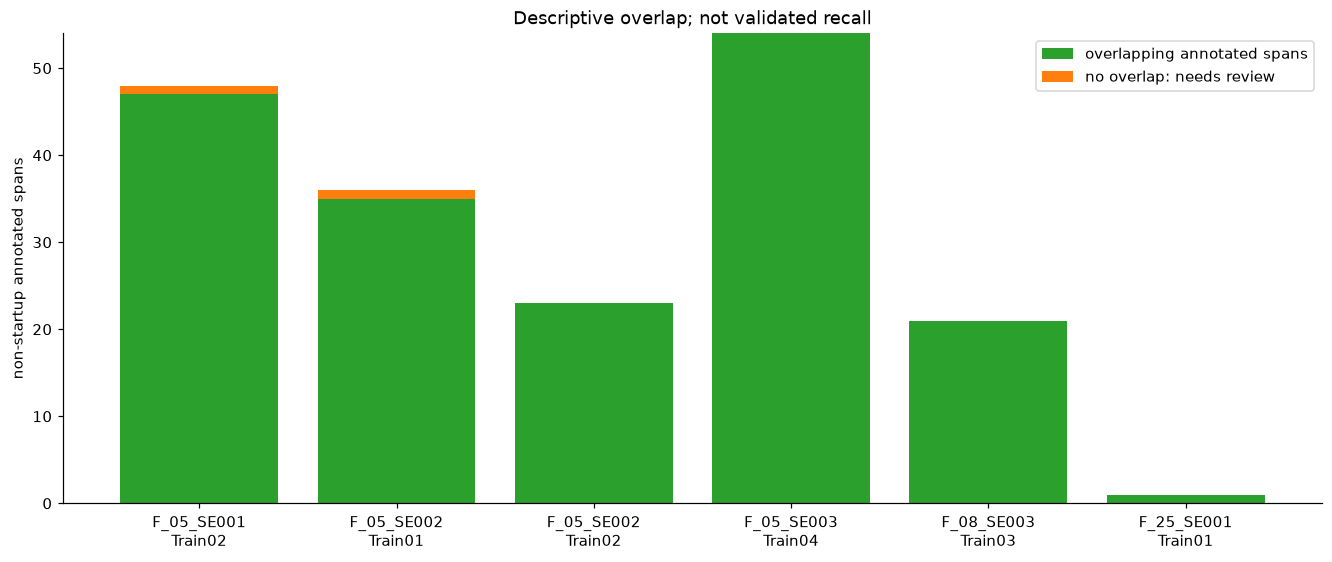

In [2]:
cols=['edf_name','in_frozen_pilot','suspected_manual_spans','startup_spans','nonstartup_spans',
      'nonstartup_spans_with_overlap','nonstartup_spans_without_overlap','auto_candidates','source_consistency']
display(summary[cols])
print('非启动期已标段与候选重叠：',summary.nonstartup_spans_with_overlap.sum(),'/',summary.nonstartup_spans.sum())
fig,ax=plt.subplots(figsize=(12,5),layout='constrained')
x=np.arange(len(summary));matched=summary.nonstartup_spans_with_overlap
ax.bar(x,matched,label='overlapping annotated spans',color='tab:green')
ax.bar(x,summary.nonstartup_spans_without_overlap,bottom=matched,label='no overlap: needs review',color='tab:orange')
ax.set(xticks=x,xticklabels=[f'{r.edf_name.split("_CBCol")[0]}\n{r.edf_name.split("_CBCol_")[1].removesuffix(".edf")}' for r in summary.itertuples()],ylabel='non-startup annotated spans',title='Descriptive overlap; not validated recall')
ax.legend();plt.show()

## 2. 尚未与候选重叠的人工片段

下面列出所有非启动期的未相交标注。它们值得逐段复核，但在稀疏、疑似眨眼标注条件下，不能直接宣布为确定漏检。辅助因果分支会改变波形时序，狭窄的人工区间也可能与候选边界错开。

max_overlapping_epoch_ptp_uv是与人工区间相交的epoch里、全通道最大PTP，不是眨眼波形自身幅值，不能直接用于重设眨眼检测门槛。

In [3]:
unmatched=pd.read_csv(OUT/'unmatched_nonstartup_manual.csv')
display(unmatched[['edf_name','manual_id','start_sec','end_sec','overlap_epochs','max_overlapping_epoch_ptp_uv']])
print('未重叠详细记录：',OUT/'unmatched_nonstartup_manual.csv')

,edf_name,manual_id,start_sec,end_sec,overlap_epochs,max_overlapping_epoch_ptp_uv
0,F_05_SE001_CBCol_Train02.edf,F_05_SE001_CBCol_Train02_M0031,89.500282,89.636914,4,106.573122
1,F_05_SE002_CBCol_Train01.edf,F_05_SE002_CBCol_Train01_M0021,55.614507,56.062850,5,194.055737


未重叠详细记录： D:\BCI_project\bigp3bci-personalized-strategies\outputs\blink_annotation_update\unmatched_nonstartup_manual.csv


## 3. 人工区间覆盖程度与边界差

某候选与人工区间只相交一点也会计为“有重叠”，因此补看人工区间有多少时长被候选覆盖，以及相交对的起止差。注意人工标注在原始信号域，候选在额外因果低通分支上，边界差混合了滤波相位和人工边界误差，不是已验证定位精度。

同一个候选可能跨多个人工标注，同一人工标注也可能与多个候选相交；下表按配对描述，不能把配对数当作独立事件数。

,count,min,median,mean,max
edf_name,,,,,
F_05_SE001_CBCol_Train02.edf,48,0.000000,0.552284,0.547569,1.000000
F_05_SE002_CBCol_Train01.edf,36,0.000000,0.598397,0.600877,1.000000
F_05_SE002_CBCol_Train02.edf,23,0.455338,0.656825,0.661657,1.000000
F_05_SE003_CBCol_Train04.edf,54,0.399753,0.680515,0.671671,1.000000
F_08_SE003_CBCol_Train03.edf,21,0.574652,0.714243,0.762975,1.000000
F_25_SE001_CBCol_Train01.edf,1,0.653655,0.653655,0.653655,0.653655


overlap_seconds                                \
                                       count    median       min       max   
edf_name                                                                     
F_05_SE001_CBCol_Train02.edf              50  0.162111  0.026011  0.344879   
F_05_SE002_CBCol_Train01.edf              38  0.181518  0.040374  0.287180   
F_05_SE002_CBCol_Train02.edf              25  0.197458  0.123549  0.349318   
F_05_SE003_CBCol_Train04.edf              60  0.218645  0.111191  0.428980   
F_08_SE003_CBCol_Train03.edf              22  0.248263  0.170790  0.414598   
F_25_SE001_CBCol_Train01.edf               2  0.124318  0.099850  0.148785   

                             onset_difference_seconds                      \
                                                count    median       min   
edf_name                                                                    
F_05_SE001_CBCol_Train02.edf                       50  0.135684 -0.271070   
F_05_SE002_CBCol_Train01.edf                       38  0.120361 -0.198774   
F_05_SE002_CBCol_Train02.edf                       25  0.099025 -0.597298   
F_05_SE003_CBCol_Train04.edf                       60  0.110057 -0.352522   
F_08_SE003_CBCol_Train03.edf                       22  0.086651 -0.357947   
F_25_SE001_CBCol_Train01.edf                        2  0.141239  0.078835   

                                       offset_difference_seconds            \
                                   max                     count    median   
edf_name                                                                     
F_05_SE001_CBCol_Train02.edf  0.295075                        50  0.197825   
F_05_SE002_CBCol_Train01.edf  0.211746                        38  0.257117   
F_05_SE002_CBCol_Train02.edf  0.184086                        25  0.244277   
F_05_SE003_CBCol_Train04.edf  0.326258                        60  0.209405   
F_08_SE003_CBCol_Train03.edf  0.212623                        22  0.261644   
F_25_SE001_CBCol_Train01.edf  0.203644                         2  0.436229   

                                                  
                                   min       max  
edf_name                                          
F_05_SE001_CBCol_Train02.edf -0.093109  0.746975  
F_05_SE002_CBCol_Train01.edf  0.103445  0.887907  
F_05_SE002_CBCol_Train02.edf  0.146636  0.950576  
F_05_SE003_CBCol_Train04.edf -0.029173  0.896552  
F_08_SE003_CBCol_Train03.edf  0.085635  0.909752  
F_25_SE001_CBCol_Train01.edf  0.208744  0.663715

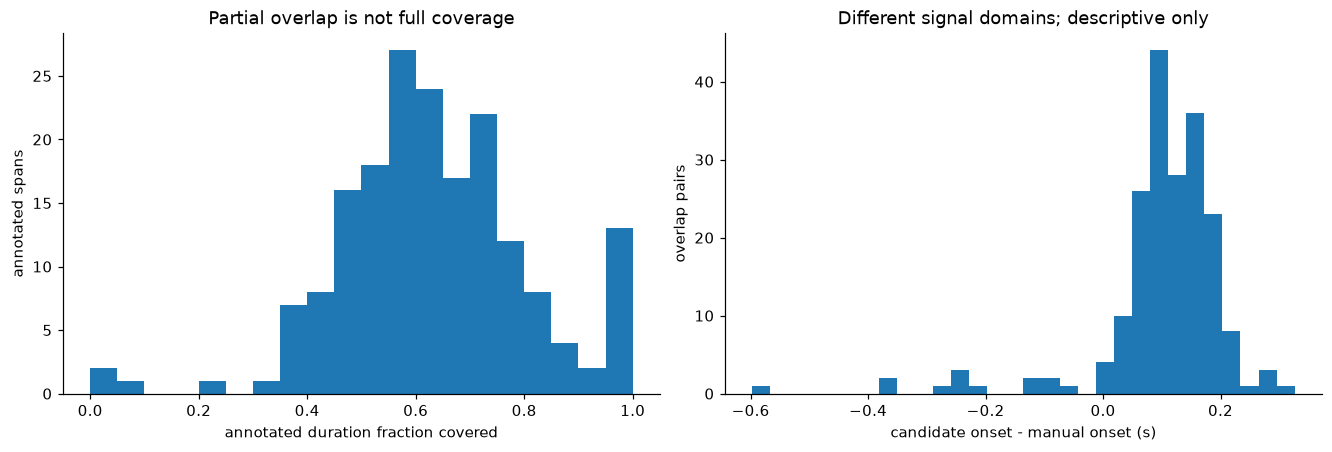

In [4]:
d=detail[~detail.startup]
display(d.groupby('edf_name').manual_duration_covered_fraction.agg(['count','min','median','mean','max']))
display(pairs.groupby('edf_name')[['overlap_seconds','onset_difference_seconds','offset_difference_seconds']].agg(['count','median','min','max']))
fig,axes=plt.subplots(1,2,figsize=(12,4),layout='constrained')
axes[0].hist(d.manual_duration_covered_fraction,bins=np.linspace(0,1,21))
axes[0].set(xlabel='annotated duration fraction covered',ylabel='annotated spans',title='Partial overlap is not full coverage')
axes[1].hist(pairs.onset_difference_seconds,bins=30)
axes[1].set(xlabel='candidate onset - manual onset (s)',ylabel='overlap pairs',title='Different signal domains; descriptive only')
plt.show()

## 4. 所有已处理文件：固定pilot与补充文件分开

这张表覆盖原8份文件和本次4份补充训练文件，不重复计算已在pilot内的已标注文件。manually_annotated=False表示没有找到当前人工标注，并不表示正常。没有候选也不代表该文件无眨眼。

仅汇总候选数、关联epoch数、启动epoch与基础跳变。站点全部仍为inferred，未按候选结果改动原固定文件清单。

In [5]:
display(all_files[['edf_name','site','in_frozen_pilot','manually_annotated','flashes','auto_candidates',
                   'nonstartup_auto_candidates','epochs_with_candidate','filter_startup_epochs','jump_candidates','other_basic_candidates']])
for name,g in all_files.groupby('in_frozen_pilot'):
    print('原固定pilot' if name else '人工标注补充文件',':',len(g),'files;',g.flashes.sum(),'flashes;',g.auto_candidates.sum(),'candidates')

,edf_name,site,in_frozen_pilot,manually_annotated,flashes,auto_candidates,nonstartup_auto_candidates,epochs_with_candidate,filter_startup_epochs,jump_candidates,other_basic_candidates
0,F_03_SE001_CBCol_Train01.edf,ETSU,True,False,756,3,2,0,22,0,0
1,F_03_SE002_CBCol_Train01.edf,ETSU,True,False,756,6,3,12,22,0,0
2,F_05_SE001_CBCol_Train02.edf,Duke,True,True,756,95,91,333,22,15,0
3,F_05_SE002_CBCol_Train01.edf,Duke,True,True,756,102,97,418,22,117,0
4,F_06_SE001_CBCol_Train01.edf,Duke,True,False,756,2,2,0,22,0,0
5,F_06_SE002_CBCol_Train01.edf,Duke,True,False,756,0,0,0,22,27,0
6,F_20_SE001_CBCol_Train01.edf,ETSU,True,False,756,6,6,4,22,0,0
7,F_20_SE002_CBCol_Train01.edf,ETSU,True,False,738,12,11,18,22,0,0
8,F_05_SE002_CBCol_Train02.edf,Duke,False,True,756,126,123,509,22,38,0
9,F_05_SE003_CBCol_Train04.edf,Duke,False,True,756,140,133,509,22,9,0


人工标注补充文件 : 4 files; 3024 flashes; 369 candidates
原固定pilot : 8 files; 6030 flashes; 226 candidates


## 5. 自动候选没有人工重叠，如何解释？

下表给出已标注文件内的自动候选数，以及没有与任何已保存标注相交的数量。这些候选可能是未标出的眨眼，也可能是其他额区变化；**不能称为误报，不能算精确率**。同样，人工有重叠的候选也只是疑似匹配，不是确诊眼动来源。

要评价漏检和误报，需要完整检查的连续区间及明确不确定片段。当前reviewed_intervals仍缺少，程序没有生成ground truth。

In [6]:
display(summary[['edf_name','nonstartup_auto_candidates','nonstartup_auto_candidates_overlapping_manual',
                 'auto_candidates_without_manual_overlap','complete_reviewed_intervals','reviewed_event_recall','reviewed_candidate_match_fraction']])
print('注意auto_candidates_without_manual_overlap包含启动期候选；其他两列明确仅非启动期。')

,edf_name,nonstartup_auto_candidates,nonstartup_auto_candidates_overlapping_manual,auto_candidates_without_manual_overlap,complete_reviewed_intervals,reviewed_event_recall,reviewed_candidate_match_fraction
0,F_05_SE001_CBCol_Train02.edf,91,46,46,0,NaN,NaN
1,F_05_SE002_CBCol_Train01.edf,97,35,64,0,NaN,NaN
2,F_05_SE002_CBCol_Train02.edf,123,23,101,0,NaN,NaN
3,F_05_SE003_CBCol_Train04.edf,133,53,81,1,1.0,0.8
4,F_08_SE003_CBCol_Train03.edf,31,21,11,1,1.0,1.0
5,F_25_SE001_CBCol_Train01.edf,65,1,68,0,NaN,NaN


注意auto_candidates_without_manual_overlap包含启动期候选；其他两列明确仅非启动期。


## 6. PTP方案模拟与眨眼候选分开

下表仍只模拟150/250µV上限与无上限方案的预计有效epoch数。基础条件相同；眨眼候选不参与拒绝。no_upper也仍保留启动、不完整、非有限、恢复、原始平线与过低PTP等条件。

新增标注只帮助检查检测器，不意味着需要调PTP上限。PTP不是眨眼来源特异指标，不能因希望覆盖所有眨眼而直接降低到大量拒绝的数值。

In [7]:
display(all_files[['edf_name','flashes','all16_upper_150uv_expected_kept','all16_upper_250uv_expected_kept','all16_no_upper_expected_kept']])
params=json.loads((ROOT/'configs/expanded_pilot.json').read_text())
display(pd.Series(params['blink_detector'],name='unchanged candidate parameter').to_frame())

,edf_name,flashes,all16_upper_150uv_expected_kept,all16_upper_250uv_expected_kept,all16_no_upper_expected_kept
0,F_03_SE001_CBCol_Train01.edf,756,734,734,734
1,F_03_SE002_CBCol_Train01.edf,756,734,734,734
2,F_05_SE001_CBCol_Train02.edf,756,729,734,734
3,F_05_SE002_CBCol_Train01.edf,756,629,734,734
4,F_06_SE001_CBCol_Train01.edf,756,725,734,734
5,F_06_SE002_CBCol_Train01.edf,756,734,734,734
6,F_20_SE001_CBCol_Train01.edf,756,734,734,734
7,F_20_SE002_CBCol_Train01.edf,738,716,716,716
8,F_05_SE002_CBCol_Train02.edf,756,501,734,734
9,F_05_SE003_CBCol_Train04.edf,756,731,734,734


,unchanged candidate parameter
status,unvalidated engineering candidates; fixed para...
frontal_channels,"[EEG_F3, EEG_Fz, EEG_F4]"
posterior_channels,"[EEG_Pz, EEG_PO7, EEG_PO8, EEG_Oz]"
auxiliary_lowpass_hz,5.0
auxiliary_order,2
entry_uv,20.0
exit_uv,10.0
min_frontal_amplitude_uv,25.0
min_support_channels,2
support_peak_fraction,0.5


## 7. 当前结论与一致性检查

当前不自动调整阈值。先看新增文件是否重复出现特定的未匹配波形或边界模式，再用完整检查的区间评估降低门槛的代价。已标正例的高重叠比例本身不足以确定参数最优。

同一F_05多个Session并非多个独立被试；六份标注集中在少数被试，跨被试泛化证据仍有限。补充文件因有人工标注而被选入，也不是独立盲测。

重复运行：`D:/Anaconda/envs/bigp3bci/python.exe scripts/check_blink_annotation_updates.py`。检测参数和原固定8文件manifest的hash在处理前后保持一致；旧检测结果可复用，新增文件的原始EDF处理前后hash同样保存。下列检查只验证产物一致性，不证明检测有效。

In [8]:
assert summary.source_consistency.eq('CSV_FIF_agree').all()
assert summary.suspected_manual_spans.sum()==len(detail)
assert summary.nonstartup_spans.sum()==detail.startup.eq(False).sum()
assert summary.nonstartup_spans_with_overlap.sum()==((~detail.startup)&detail.has_nonstartup_candidate_overlap).sum()
assert len(all_files)==all_files.edf_name.nunique()
assert record['config_unchanged'] and record['frozen_manifest_unchanged']
unreviewed=summary.complete_reviewed_intervals.eq(0)
assert summary.loc[unreviewed,'reviewed_event_recall'].isna().all()
assert summary.loc[unreviewed,'reviewed_candidate_match_fraction'].isna().all()
print('PASS: annotation sources, counts, unique files, unchanged parameters and unavailable validation metrics')

PASS: annotation sources, counts, unique files, unchanged parameters and unavailable validation metrics


## 8. ????F_08 SE003 Train03?????1?50?

???????????10?50???4??????4???????????????????????????????????????

49.844?50.852???????????????????51.004?????????????????????????49.720?50.055?????

1?10???????1.527?2.000???????????2.316?2.630??3.395?3.826????????????????????????????

??????????????????????????????????????

In [9]:
f08=OUT/'per_edf/F_08_SE003_CBCol_Train03'
display(pd.Series(json.loads((f08/'manual_validation_status.json').read_text()),name='reviewed F08 status').to_frame())
c=pd.read_csv(f08/'manual_candidate_comparison.csv')
display(c.loc[c.onset_seconds<51,['blink_candidate_id','onset_seconds','offset_seconds','decision_seconds','filter_startup','fully_reviewed','evaluation_status']])
m=pd.read_csv(f08/'manual_event_comparison.csv')
display(m.loc[m.start_sec<51,['manual_id','start_sec','end_sec','matching_candidate_ids','evaluation_status']])
assert c.loc[c.evaluation_eligible,'evaluation_status'].eq('matched').all()

,reviewed F08 status
edf_name,F_08_SE003_CBCol_Train03.edf
manual_sources,"[""outputs\\artifact_qc\\continuous_manual_qc\\..."
manual_source_consistency,agree
suspected_manual_blinks,24
complete_reviewed_intervals,1
reviewed_seconds,49.0
evaluated_manual_events,4
evaluated_candidates,4
matched_manual_events,4
unmatched_candidates,0


,blink_candidate_id,onset_seconds,offset_seconds,decision_seconds,filter_startup,fully_reviewed,evaluation_status
0,F_08_SE003_CBCol_Train03_B0001,0.878906,1.363281,1.515625,True,False,unreviewed_or_boundary_or_startup
1,F_08_SE003_CBCol_Train03_B0002,1.527344,2.000000,2.152344,True,True,unreviewed_or_boundary_or_startup
2,F_08_SE003_CBCol_Train03_B0003,16.710938,17.699219,17.851562,False,True,matched
3,F_08_SE003_CBCol_Train03_B0004,26.457031,26.902344,27.054688,False,True,matched
4,F_08_SE003_CBCol_Train03_B0005,35.949219,36.953125,37.105469,False,True,matched
5,F_08_SE003_CBCol_Train03_B0006,38.117188,38.925781,39.078125,False,True,matched
6,F_08_SE003_CBCol_Train03_B0007,49.843750,50.851562,51.003906,False,False,unreviewed_or_boundary_or_startup


,manual_id,start_sec,end_sec,matching_candidate_ids,evaluation_status
0,F_08_SE003_CBCol_Train03_M0001,0.806129,1.099888,F_08_SE003_CBCol_Train03_B0001,not_evaluable_sparse_or_boundary_or_startup
1,F_08_SE003_CBCol_Train03_M0002,2.315912,2.630166,NaN,not_evaluable_sparse_or_boundary_or_startup
2,F_08_SE003_CBCol_Train03_M0003,3.395305,3.825696,NaN,not_evaluable_sparse_or_boundary_or_startup
3,F_08_SE003_CBCol_Train03_M0004,16.498314,17.010684,F_08_SE003_CBCol_Train03_B0003,matched
4,F_08_SE003_CBCol_Train03_M0005,26.382849,26.642449,F_08_SE003_CBCol_Train03_B0004,matched
5,F_08_SE003_CBCol_Train03_M0006,35.865110,36.363816,F_08_SE003_CBCol_Train03_B0005,matched
6,F_08_SE003_CBCol_Train03_M0007,38.365475,38.652402,F_08_SE003_CBCol_Train03_B0006,matched
7,F_08_SE003_CBCol_Train03_M0008,49.719934,50.054682,F_08_SE003_CBCol_Train03_B0007,not_evaluable_sparse_or_boundary_or_startup


---

## 历史实验 / 专项复核：bigp3bci_blink_candidate_review

# 主波眨眼候选复核

窗口显示橙色主波和本轮复核标记，并恢复flash事件竖线：红色为target，绿色为non-target，灰色为未知标签。旧候选区间、恢复区间和历史标注仍隐藏。使用 `BAD` 标记你认为多检的部分，再点击“保存窗口复核”。

原始EDF、自动检测参数和已有人工标注不变。主波边界仍是待复核估计，并不代表主波结束后信号一定干净。如果旧窗口还有未保存标记，请先使用下面的补存单元，不要先重启内核或运行全部单元。


## 已经用BAD画过标记：先补存

仅在原来的内核和窗口仍在时，单独运行下一格。它重新加载已修复的保存函数，尝试保存当前窗口中的 `BAD`、`bad`、`BAD_*` 或 `REVIEW_*` 标记。

如果提示没有活动窗口或没有标记，就没有保存成功；磁盘空文件不能恢复已经丢失的内存标记。补存成功后，再重新运行第3节面板。


In [1]:
from pathlib import Path
import sys,importlib
_rescue_root=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'configs/expanded_pilot.json').exists())
if str(_rescue_root/'src') not in sys.path:sys.path.insert(0,str(_rescue_root/'src'))
import bigp3bci_candidate_review as candidate_review
importlib.reload(candidate_review)
_existing_panel=globals().get('panel_state',{})
_existing_raw=_existing_panel.get('raw')
if _existing_raw is None:
    _existing_raw=globals().get('browser_raw')
if _existing_raw is None:
    print('未找到当前内核中的复核窗口；本单元没有写文件。首次使用可继续运行后面的单元。')
else:
    from collections import Counter
    print('当前窗口标签：',dict(Counter(map(str,_existing_raw.annotations.description))))
    _n=sum(candidate_review.normalize_review_label(label) is not None and duration>0 for label,duration in zip(_existing_raw.annotations.description,_existing_raw.annotations.duration))
    if not _n:
        print('当前对象没有可保存的BAD或REVIEW标记，未覆盖磁盘文件。')
    else:
        _edf=getattr(_existing_raw,'_blink_review_edf',None)
        _csv,_fif,_spans=candidate_review.save_review_spans(_rescue_root,_edf,_existing_raw)
        if _existing_panel.get('raw') is _existing_raw and '_span_signature' in globals():
            _existing_panel['saved_signature']=_span_signature(_existing_raw)
        print('成功补存',_n,'段：',_fif)
        print('候选复核表：',_csv)
        display(_spans)


未找到当前内核中的复核窗口；本单元没有写文件。首次使用可继续运行后面的单元。


In [2]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'configs/expanded_pilot.json').exists())
if str(ROOT/'src') not in sys.path:sys.path.insert(0,str(ROOT/'src'))
from bigp3bci_candidate_review import load_candidate_review,open_candidate_review
INDEX=pd.read_csv(ROOT/'outputs/blink_candidate_review/file_index.csv')
display(INDEX[['edf_name','candidate_count','nonstartup_candidates','annotation_reload_verified']])


,edf_name,candidate_count,nonstartup_candidates,annotation_reload_verified
0,F_03_SE001_CBCol_Train01.edf,3,2,True
1,F_03_SE002_CBCol_Train01.edf,6,3,True
2,F_05_SE001_CBCol_Train02.edf,95,91,True
3,F_05_SE002_CBCol_Train01.edf,102,97,True
4,F_06_SE001_CBCol_Train01.edf,2,2,True
5,F_06_SE002_CBCol_Train01.edf,0,0,True
6,F_20_SE001_CBCol_Train01.edf,6,6,True
7,F_20_SE002_CBCol_Train01.edf,12,11,True
8,F_05_SE002_CBCol_Train02.edf,126,123,True
9,F_05_SE003_CBCol_Train04.edf,140,133,True


## 1. 选择文件和波形

这里只叠加新版主波。`raw` 为原始EEG，便于查看上升和回落；`analysis` 为正式因果滤波信号，`auxiliary` 为旧检测器的辅助分支。切换波形不会移动标注或修改参数。

下面先生成静态预览；交互窗口在第3节打开。


In [3]:
EDF_NAME='F_05_SE003_CBCol_Train04.edf'
MODE='raw'
START_SECONDS=10.0
DURATION_SECONDS=12.0
review_raw,flash_events,candidates,review_csv=load_candidate_review(ROOT,EDF_NAME,MODE,include_manual=False,main_only=True)
display(candidates[['blink_candidate_id','onset_seconds','peak_seconds','offset_seconds','filter_startup','localization_flags']].head(20))
print('候选复核表：',review_csv)


,blink_candidate_id,onset_seconds,peak_seconds,offset_seconds,filter_startup,localization_flags
0,F_05_SE003_CBCol_Train04_B0001,0.570312,0.906250,1.519531,True,possible_adjacent_main_lobes
1,F_05_SE003_CBCol_Train04_B0002,1.894531,2.046875,2.445312,True,possible_adjacent_main_lobes
2,F_05_SE003_CBCol_Train04_B0003,2.433594,2.492188,2.582031,True,
3,F_05_SE003_CBCol_Train04_B0004,3.515625,3.605469,4.410156,True,main_offset_unconfirmed
4,F_05_SE003_CBCol_Train04_B0005,6.671875,6.746094,6.886719,True,
5,F_05_SE003_CBCol_Train04_B0006,6.875000,7.207031,7.671875,True,
6,F_05_SE003_CBCol_Train04_B0007,8.617188,8.710938,8.894531,True,
7,F_05_SE003_CBCol_Train04_B0008,11.292969,11.359375,11.480469,False,
8,F_05_SE003_CBCol_Train04_B0009,13.500000,13.617188,13.777344,False,
9,F_05_SE003_CBCol_Train04_B0010,13.781250,14.191406,14.996094,False,main_offset_unconfirmed;main_duration_outside_...


候选复核表： D:\BCI_project\bigp3bci-personalized-strategies\outputs\blink_candidate_review\F_05_SE003_CBCol_Train04\review_decisions.csv


## 2. 主波静态预览

橙色区间为暂定主波；其他彩色区间仅为本轮已保存的复核标记。主波边界仍需人工检查，不表示其后恢复区间没有污染。


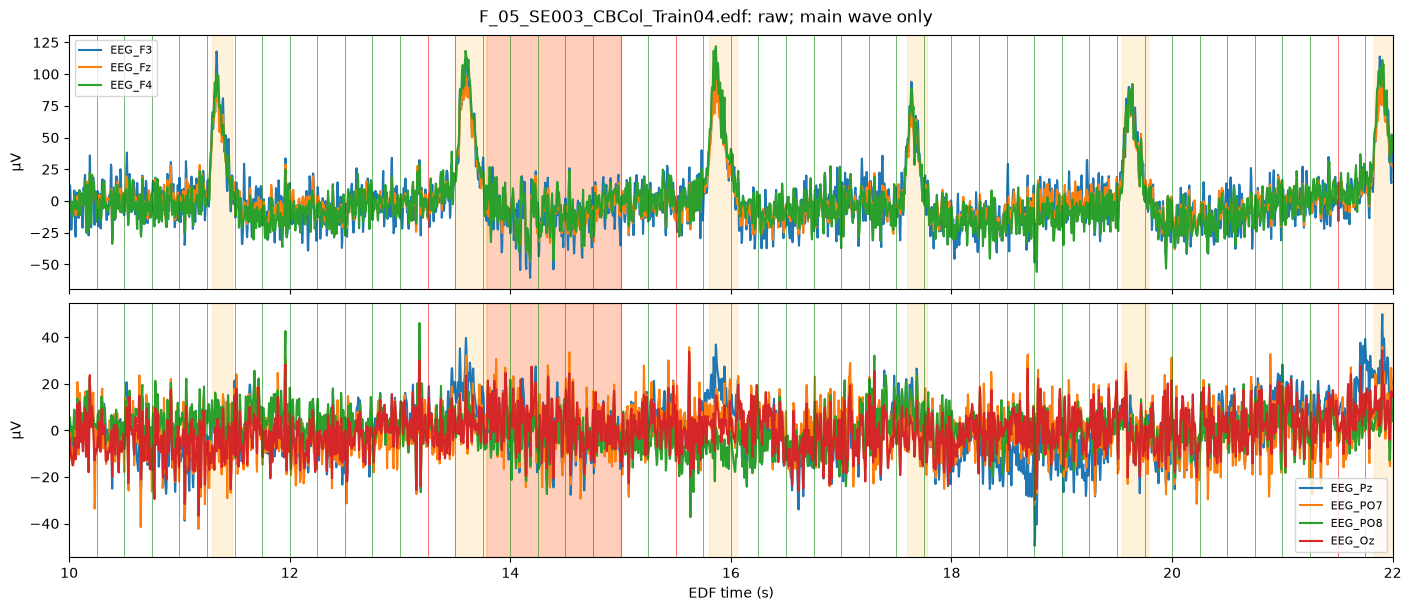

In [4]:
fs=float(review_raw.info['sfreq'])
a=round(START_SECONDS*fs);b=min(review_raw.n_times,a+round(DURATION_SECONDS*fs))
fig,axes=plt.subplots(2,1,figsize=(14,6),sharex=True,layout='constrained')
for ax,names in zip(axes,[['EEG_F3','EEG_Fz','EEG_F4'],['EEG_Pz','EEG_PO7','EEG_PO8','EEG_Oz']]):
    values=review_raw.get_data(picks=names,start=a,stop=b)*1e6
    for name,v in zip(names,values):ax.plot(np.arange(a,b)/fs,v,label=name)
    for on,duration,label in zip(review_raw.annotations.onset,review_raw.annotations.duration,review_raw.annotations.description):
        if on<b/fs and on+duration>a/fs and str(label).startswith(('CANDIDATE_blink_main','REVIEW_')):
            ax.axvspan(on,on+duration,alpha=.14,color='orange' if label=='CANDIDATE_blink_main' else 'red')
    for sample,_,event_code in flash_events:
        if a<=sample<b:
            ax.axvline(sample/fs,color={1:'green',2:'red',3:'gray'}.get(int(event_code),'gray'),lw=.6,alpha=.65)
    ax.set(ylabel='µV',xlim=(a/fs,b/fs));ax.legend(fontsize=8)
axes[-1].set_xlabel('EDF time (s)')
fig.suptitle(f'{EDF_NAME}: {MODE}; main wave only')
plt.show()


## 3. 交互窗口：抽选文件并标记“多检”

运行下一格出现控制面板，选择EDF、波形模式和候选，点击 **打开/定位候选** 即弹出16通道可滚动窗口。程序使用已安装的PyQt5与MNE matplotlib浏览器，不需要额外安装mne-qt-browser。可先查看原始EEG，再切到analysis/auxiliary对照；检测参数不变。

**两种复核方法：**

- 对完整候选下结论：选择候选后点“多检/不是眨眼”“确认眨眼”或“不确定”。自动单独保存该ID的复核决定，并在内存中加红色REVIEW标记。
- 在窗口里划片段：按 `a` 进入annotation模式，新建标签 `REVIEW_not_blink`（多检），也可使用 `REVIEW_confirmed_blink`、`REVIEW_uncertain`。拖出区间后点面板的“保存窗口复核”。区间包含候选峰时，决定才会关联到该候选ID；没包含峰的片段仍保存，但需你核对对应关系。

**不要直接删除橙色主波来表示多检。** 可以直接使用默认的 `BAD` 标签标记多检，再点击“保存窗口复核”。显示橙色主波、本轮复核标记和flash竖线（红色target、绿色non-target、灰色未知）；旧区间、恢复区间和历史标注隐藏。主波复核单独保存，不覆盖EDF、自动候选或历史人工标注。再次打开会恢复已保存的主波复核标记。已有冲突决定保守记为uncertain，需在CSV中明确更正。

切换窗口前先保存；有未保存的REVIEW区间时程序会阻止切换。只检查选中候选不代表整段完整检查，不会自动增加reviewed_intervals。


In [ ]:
import ipywidgets as widgets
import importlib
import mne
import bigp3bci_candidate_review as candidate_review
importlib.reload(candidate_review)
from IPython.display import display,clear_output

panel_file=widgets.Dropdown(options=INDEX.edf_name.tolist(),value=EDF_NAME,description='EDF:',layout=widgets.Layout(width='560px'))
panel_mode=widgets.Dropdown(options=['raw','analysis','auxiliary'],value='raw',description='波形:')
panel_candidate=widgets.Dropdown(description='候选:',layout=widgets.Layout(width='560px'))
panel_notes=widgets.Text(value='',description='备注:',layout=widgets.Layout(width='650px'))
open_button=widgets.Button(description='打开/定位候选',button_style='primary')
false_button=widgets.Button(description='多检/不是眨眼',button_style='danger')
true_button=widgets.Button(description='确认眨眼',button_style='success')
uncertain_button=widgets.Button(description='不确定')
save_button=widgets.Button(description='保存窗口复核',button_style='info')
panel_output=widgets.Output()
panel_state={'raw':None,'browser':None,'edf':None,'saved_signature':None,'candidates':None}

def _span_signature(raw):
    if raw is None:return ()
    return tuple((round(float(a),6),round(float(d),6),str(label))
                 for a,d,label in zip(raw.annotations.onset,raw.annotations.duration,raw.annotations.description)
                 if candidate_review.normalize_review_label(label) is not None and d>0)

def _refresh_candidates(change=None):
    entry=INDEX[INDEX.edf_name.eq(panel_file.value)].iloc[0]
    c=pd.read_csv(ROOT/entry.candidate_details_csv)
    boundary=pd.read_csv(ROOT/'outputs/blink_boundary_localization_v1'/Path(panel_file.value).stem/'boundaries.csv')
    for target,source in [('onset_seconds','main_onset_seconds'),('peak_seconds','main_peak_seconds'),('offset_seconds','main_offset_seconds')]:c[target]=boundary[source].to_numpy(float)
    panel_state['candidates']=c
    panel_candidate.options=[(f'{r.blink_candidate_id.split("_B")[-1]} | {r.onset_seconds:.3f}–{r.offset_seconds:.3f}s'+(' 启动期' if r.filter_startup else ''),r.blink_candidate_id) for r in c.itertuples()]
    eligible=c[c.filter_startup.eq(False)]
    if len(eligible):panel_candidate.value=eligible.iloc[0].blink_candidate_id

panel_file.observe(_refresh_candidates,names='value')
_refresh_candidates()

def _selected_candidate():
    c=panel_state['candidates']
    selected=c[c.blink_candidate_id.eq(panel_candidate.value)]
    return None if selected.empty else selected.iloc[0]

def _open_window(button):
    with panel_output:
        clear_output(wait=True)
        try:
            current=panel_state['raw']
            if current is not None and _span_signature(current)!=panel_state['saved_signature']:
                raise RuntimeError('当前窗口有未保存REVIEW区间，请先点“保存窗口复核”。')
            get_ipython().run_line_magic('matplotlib','qt')
            mne.viz.set_browser_backend('matplotlib')
            if panel_state['browser'] is not None:
                plt.close(panel_state['browser'])
            if current is not None:current.close()
            selected=_selected_candidate()
            start=START_SECONDS if selected is None else max(0.,selected.onset_seconds-2.)
            raw,browser,_,_=candidate_review.open_candidate_review(ROOT,panel_file.value,mode=panel_mode.value,start=start,duration=12.,include_manual=False,main_only=True)
            panel_state.update(raw=raw,browser=browser,edf=panel_file.value,saved_signature=_span_signature(raw))
            print(f'已打开 {panel_file.value} / {panel_mode.value}，起点 {start:.3f}s。')
            print('按a进入标注；新建REVIEW_not_blink标多检，完成后点保存窗口复核。')
        except Exception as exc:print(type(exc).__name__+': '+str(exc))

def _save_window(button=None):
    raw=panel_state['raw']
    if raw is None:raise RuntimeError('请先打开一个文件窗口。')
    path,annotation,spans=candidate_review.save_review_spans(ROOT,panel_state['edf'],raw)
    panel_state['saved_signature']=_span_signature(raw)
    print('已保存：',path)
    print('本轮人工区间：',annotation)
    if len(spans):display(spans.tail(8))
    empty=spans[spans.blink_candidate_ids.eq('')]
    if len(empty):print('注意：',len(empty),'个区间未包含任何候选峰，已保留区间但未写候选决定。')

def _save_clicked(button):
    with panel_output:
        clear_output(wait=True)
        try:_save_window()
        except Exception as exc:print(type(exc).__name__+': '+str(exc))

def _decide(label):
    with panel_output:
        clear_output(wait=True)
        try:
            if panel_state['raw'] is None or panel_state['edf']!=panel_file.value:
                raise RuntimeError('请先打开当前选择的EDF。')
            selected=_selected_candidate()
            if selected is None:raise RuntimeError('当前文件没有候选。')
            raw=panel_state['raw']
            raw.set_annotations(raw.annotations+mne.Annotations([selected.onset_seconds],[selected.offset_seconds-selected.onset_seconds],[label],orig_time=raw.annotations.orig_time))
            _save_window()
            if panel_notes.value.strip():
                entry=INDEX[INDEX.edf_name.eq(panel_file.value)].iloc[0]
                path=ROOT/entry.review_decisions_csv
                d=pd.read_csv(path,keep_default_na=False)
                mask=d.blink_candidate_id.eq(selected.blink_candidate_id)
                d.loc[mask,'review_notes']=d.loc[mask,'review_notes'].astype(str)+'; '+panel_notes.value.strip()
                d.to_csv(path,index=False)
            print(selected.blink_candidate_id,'→',candidate_review.REVIEW_DECISIONS[label])
            print('可选择下一候选，点击“打开/定位候选”跳转。')
        except Exception as exc:print(type(exc).__name__+': '+str(exc))

open_button.on_click(_open_window)
save_button.on_click(_save_clicked)
false_button.on_click(lambda b:_decide('REVIEW_not_blink'))
true_button.on_click(lambda b:_decide('REVIEW_confirmed_blink'))
uncertain_button.on_click(lambda b:_decide('REVIEW_uncertain'))
display(widgets.VBox([panel_file,panel_mode,panel_candidate,panel_notes,
    widgets.HBox([open_button,save_button]),widgets.HBox([false_button,true_button,uncertain_button]),panel_output]))


## 4. 保存位置

主波复核单独保存在：

- `*-human-main-review-annot.fif`：本轮人工复核时间段。
- `human_main_review_spans.csv`：复核时间段及对应的候选ID。
- `review_decisions.csv`：按候选ID记录复核决定，`review_region=main` 表示复核的是主波。

旧复核文件不会被覆盖。切换文件或关闭窗口前，请先点击“保存窗口复核”，并确认下方显示保存成功。


In [6]:
display(pd.read_csv(review_csv,keep_default_na=False).head(15))
review_raw.close()
assert INDEX.annotation_reload_verified.all()
print('主波复核入口已准备好，原始EDF及历史标注未修改。')


,edf_name,blink_candidate_id,onset_seconds,peak_seconds,offset_seconds,decision_seconds,filter_startup,review_decision,review_notes,review_region
0,F_05_SE003_CBCol_Train04.edf,F_05_SE003_CBCol_Train04_B0001,0.902344,0.941406,1.339844,1.492188,True,,,
1,F_05_SE003_CBCol_Train04.edf,F_05_SE003_CBCol_Train04_B0002,1.800781,1.855469,2.132812,2.285156,True,not_blink,,main
2,F_05_SE003_CBCol_Train04.edf,F_05_SE003_CBCol_Train04_B0003,2.437500,2.507812,3.097656,3.250000,True,not_blink,,main
3,F_05_SE003_CBCol_Train04.edf,F_05_SE003_CBCol_Train04_B0004,3.582031,3.625000,4.296875,4.449219,True,not_blink,,main
4,F_05_SE003_CBCol_Train04.edf,F_05_SE003_CBCol_Train04_B0005,6.707031,6.964844,7.195312,7.347656,True,,,
5,F_05_SE003_CBCol_Train04.edf,F_05_SE003_CBCol_Train04_B0006,7.417969,7.738281,8.128906,8.281250,True,not_blink,,main
6,F_05_SE003_CBCol_Train04.edf,F_05_SE003_CBCol_Train04_B0007,8.660156,8.730469,9.148438,9.300781,True,,,
7,F_05_SE003_CBCol_Train04.edf,F_05_SE003_CBCol_Train04_B0008,11.328125,11.382812,11.734375,11.886719,False,,,
8,F_05_SE003_CBCol_Train04.edf,F_05_SE003_CBCol_Train04_B0009,13.574219,13.832031,14.035156,14.187500,False,,,
9,F_05_SE003_CBCol_Train04.edf,F_05_SE003_CBCol_Train04_B0010,14.250000,14.371094,14.621094,14.773438,False,not_blink,,main


主波复核入口已准备好，原始EDF及历史标注未修改。


---

## 历史实验 / 专项复核：bigp3bci_reviewed_blink_false_positives

# F_05 SE003 Train04：完整标注0–35秒的疑似误报核查

用户明确确认0–35秒已完整标注，已将该覆盖范围存入reviewed_intervals.csv；不是程序自行推断正常区间。只在此范围内对照。眨眼候选仍不自动拒绝epoch，检测参数不变。

10–35秒：12段人工疑似眨眼均有相交候选；15个自动候选中3个未匹配。相对人工参考的候选匹配比例为12/15=80%，未匹配比例为20%；**20%不是样本级假阳性率**。事件级人工覆盖为12/12，只反映这一已复核训练区间，不能推广到全文件或其他被试。匹配采用任意正时长相交，并非严格边界准确。

0–10秒另有1个未匹配候选，属于启动保护区，单独展示，不混入上述统计。无候选跨越35秒边界，也没有本区间候选需要等到35秒以后才能判定。


In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display,Image
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'configs/expanded_pilot.json').exists())
OUT=ROOT/'outputs/blink_annotation_update/reviewed_0_35'
t=pd.read_csv(OUT/'reviewed_candidates.csv')
display(t)
display(pd.read_csv(OUT/'suspected_false_positive_candidates.csv'))

,blink_candidate_id,onset_seconds,peak_seconds,offset_seconds,decision_seconds,startup,fully_within_review,decision_by_review_end,matched_manual_ids,unmatched_to_complete_annotation,frontal_amplitude_uv,posterior_amplitude_uv,frontal_posterior_metric
0,F_05_SE003_CBCol_Train04_B0001,0.902344,0.941406,1.339844,1.492188,True,True,True,F_05_SE003_CBCol_Train04_M0001,False,45.895809,5.185130,8.851428
1,F_05_SE003_CBCol_Train04_B0002,1.800781,1.855469,2.132812,2.285156,True,True,True,F_05_SE003_CBCol_Train04_M0002,False,54.574839,19.056927,2.863780
2,F_05_SE003_CBCol_Train04_B0003,2.437500,2.507812,3.097656,3.250000,True,True,True,F_05_SE003_CBCol_Train04_M0003,False,62.495792,3.041874,20.545158
3,F_05_SE003_CBCol_Train04_B0004,3.582031,3.625000,4.296875,4.449219,True,True,True,NaN,True,25.781811,9.917727,2.599569
4,F_05_SE003_CBCol_Train04_B0005,6.707031,6.964844,7.195312,7.347656,True,True,True,F_05_SE003_CBCol_Train04_M0004,False,54.635833,2.912846,18.756853
5,F_05_SE003_CBCol_Train04_B0006,7.417969,7.738281,8.128906,8.281250,True,True,True,F_05_SE003_CBCol_Train04_M0005,False,62.598859,2.616323,23.926273
6,F_05_SE003_CBCol_Train04_B0007,8.660156,8.730469,9.148438,9.300781,True,True,True,F_05_SE003_CBCol_Train04_M0006,False,55.071578,2.128826,25.869455
7,F_05_SE003_CBCol_Train04_B0008,11.328125,11.382812,11.734375,11.886719,False,True,True,F_05_SE003_CBCol_Train04_M0007,False,52.702614,4.653817,11.324600
8,F_05_SE003_CBCol_Train04_B0009,13.574219,13.832031,14.035156,14.187500,False,True,True,F_05_SE003_CBCol_Train04_M0008,False,56.616359,2.487545,22.759938
9,F_05_SE003_CBCol_Train04_B0010,14.250000,14.371094,14.621094,14.773438,False,True,True,NaN,True,27.076160,2.059396,13.147619


,blink_candidate_id,onset_seconds,peak_seconds,offset_seconds,decision_seconds,startup,fully_within_review,decision_by_review_end,matched_manual_ids,unmatched_to_complete_annotation,frontal_amplitude_uv,posterior_amplitude_uv,frontal_posterior_metric
0,F_05_SE003_CBCol_Train04_B0004,3.582031,3.625000,4.296875,4.449219,True,True,True,NaN,True,25.781811,9.917727,2.599569
1,F_05_SE003_CBCol_Train04_B0010,14.250000,14.371094,14.621094,14.773438,False,True,True,NaN,True,27.076160,2.059396,13.147619
2,F_05_SE003_CBCol_Train04_B0014,21.886719,22.105469,22.316406,22.468750,False,True,True,NaN,True,49.832233,2.849589,17.487518
3,F_05_SE003_CBCol_Train04_B0020,30.433594,30.667969,30.808594,30.960938,False,True,True,NaN,True,27.467875,2.286747,12.011769


## 未匹配片段波形

每图四行依次为原始额区、正式分析额区、正式分析后部、辅助慢分支。绿色=人工标注，橙色=自动候选，红虚线=此未匹配候选的峰，紫点线=其判定时间，灰竖线=flash。

这些是相对于完整人工标注的**疑似误报**，仍应复核是否是眨眼后的反向恢复波被拆成第二个候选、其他共同额区变化，或人工边界太窄。辅助因果分支增加的延迟可能造成边界错位；不能仅靠未相交就断定具体原因。


### 3.582–4.297秒（启动期，单独报告）

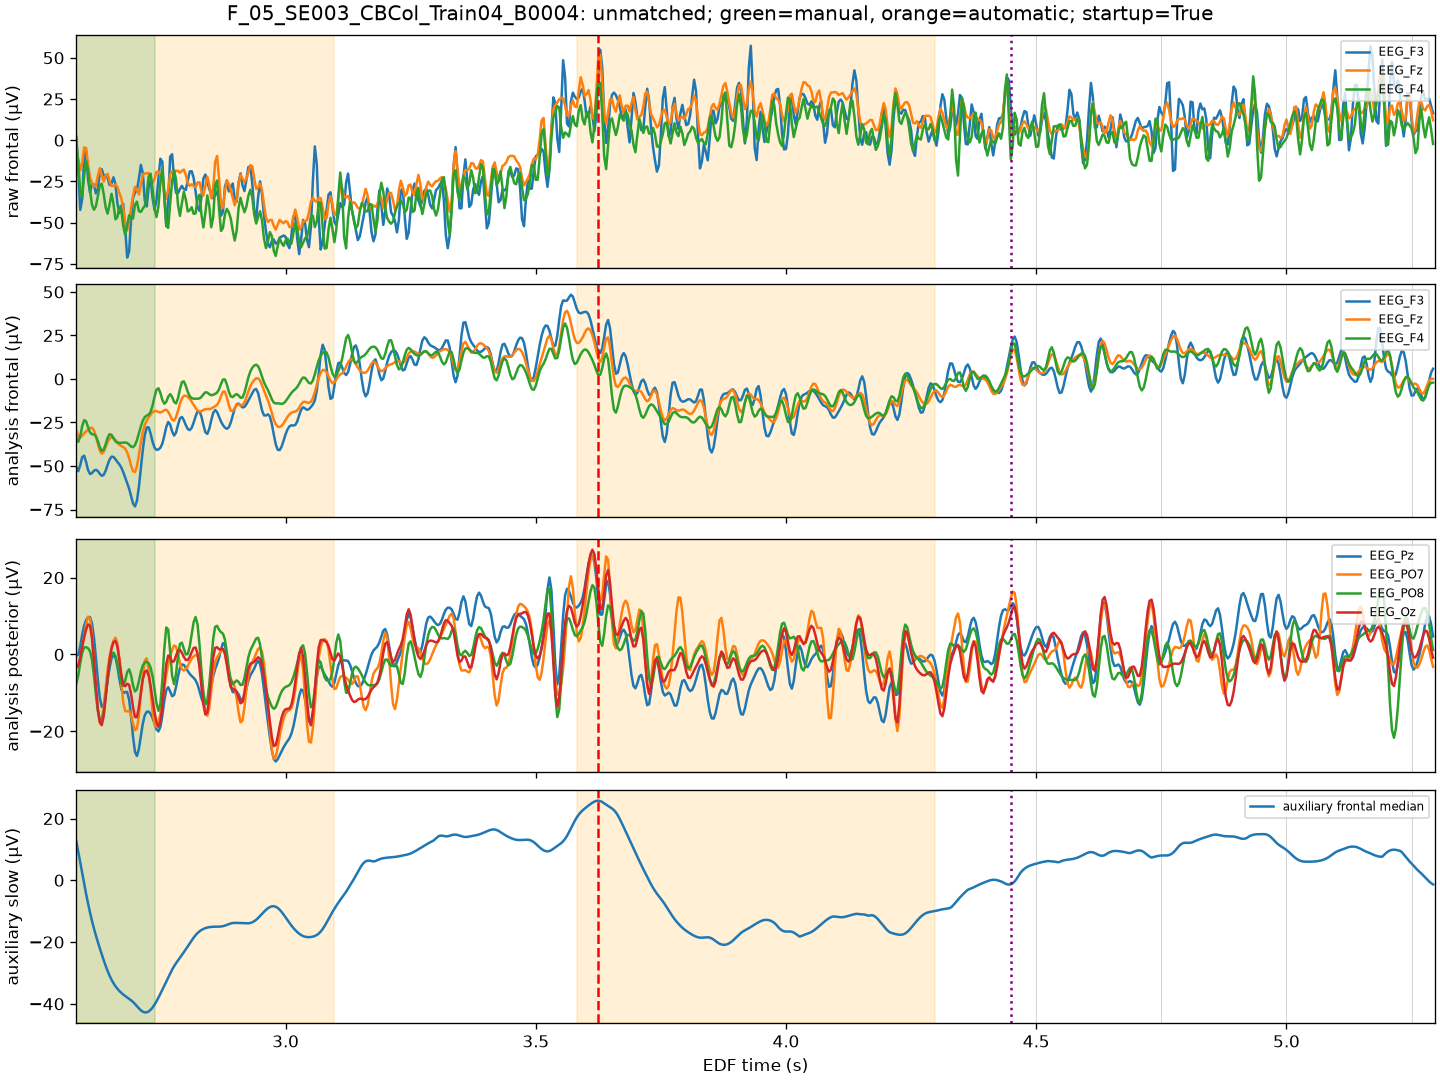

In [2]:
display(Image(filename=str(OUT/'F_05_SE003_CBCol_Train04_B0004.png'),width=1100))

### 14.250–14.621秒

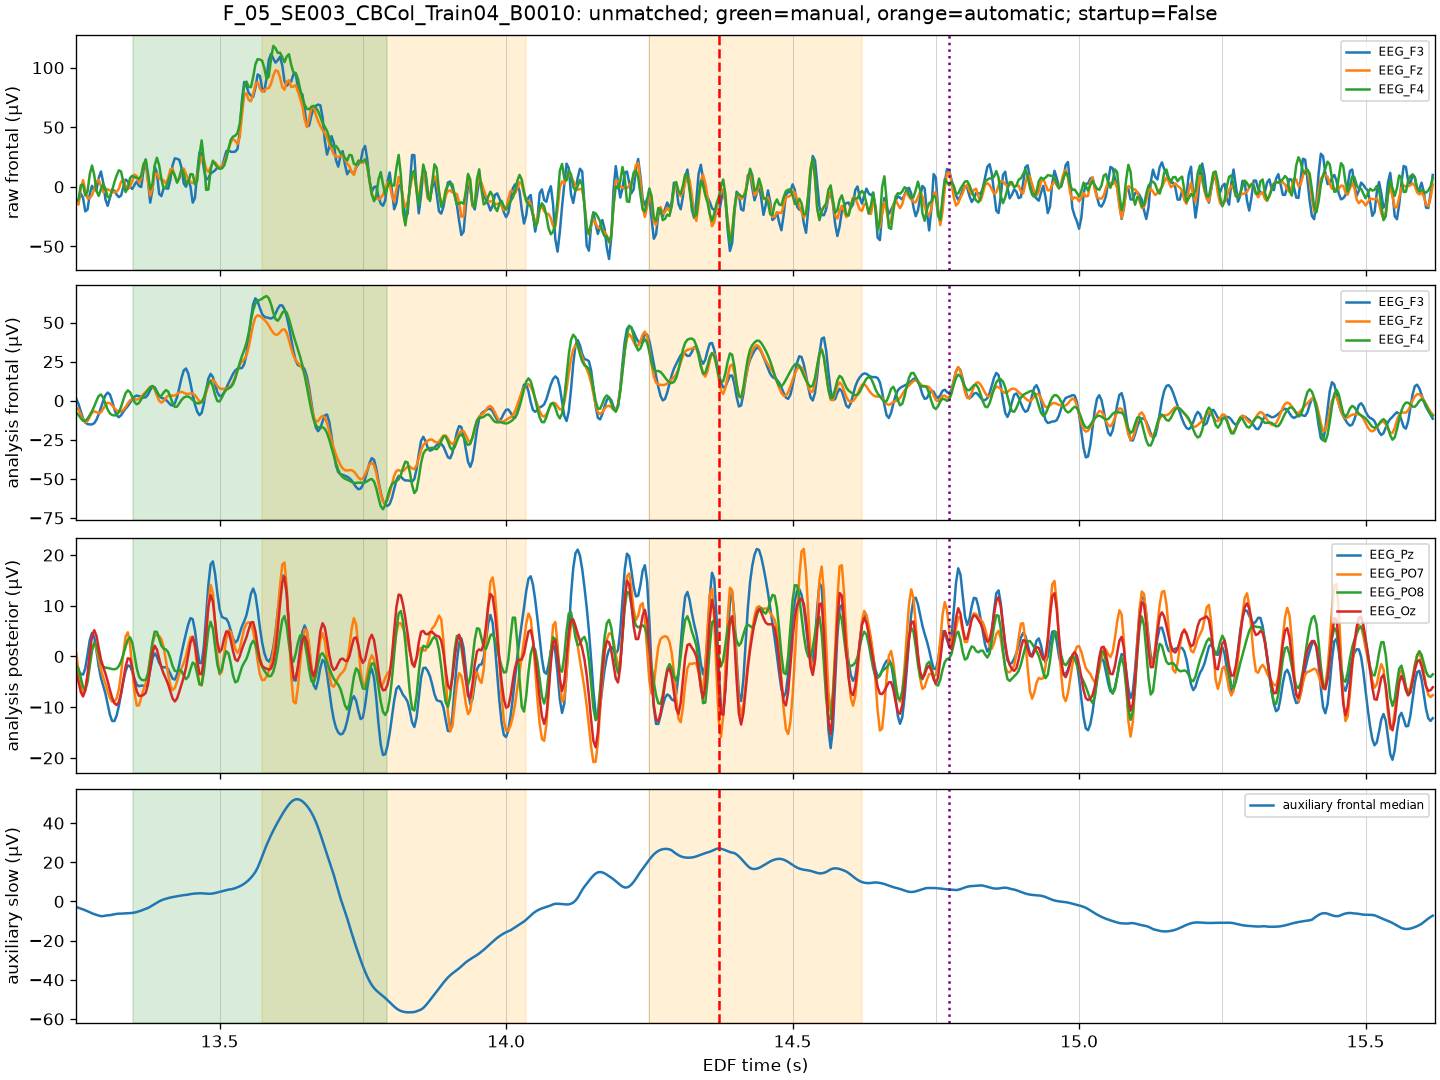

In [3]:
display(Image(filename=str(OUT/'F_05_SE003_CBCol_Train04_B0010.png'),width=1100))

### 21.887–22.316秒

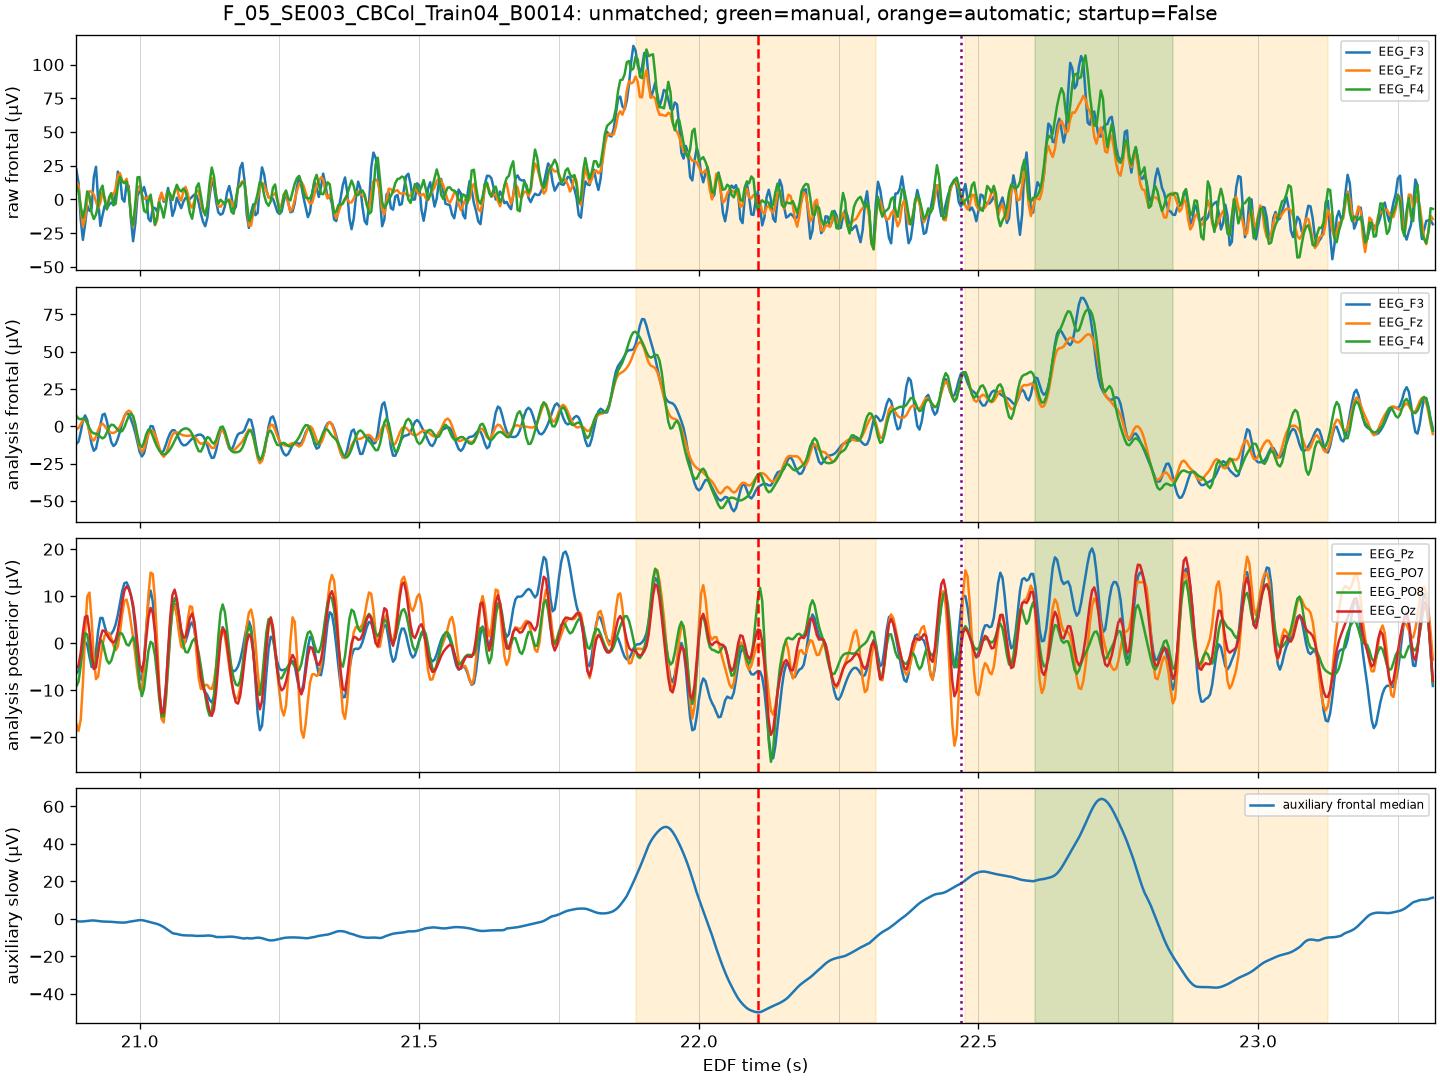

In [4]:
display(Image(filename=str(OUT/'F_05_SE003_CBCol_Train04_B0014.png'),width=1100))

### 30.434–30.809秒

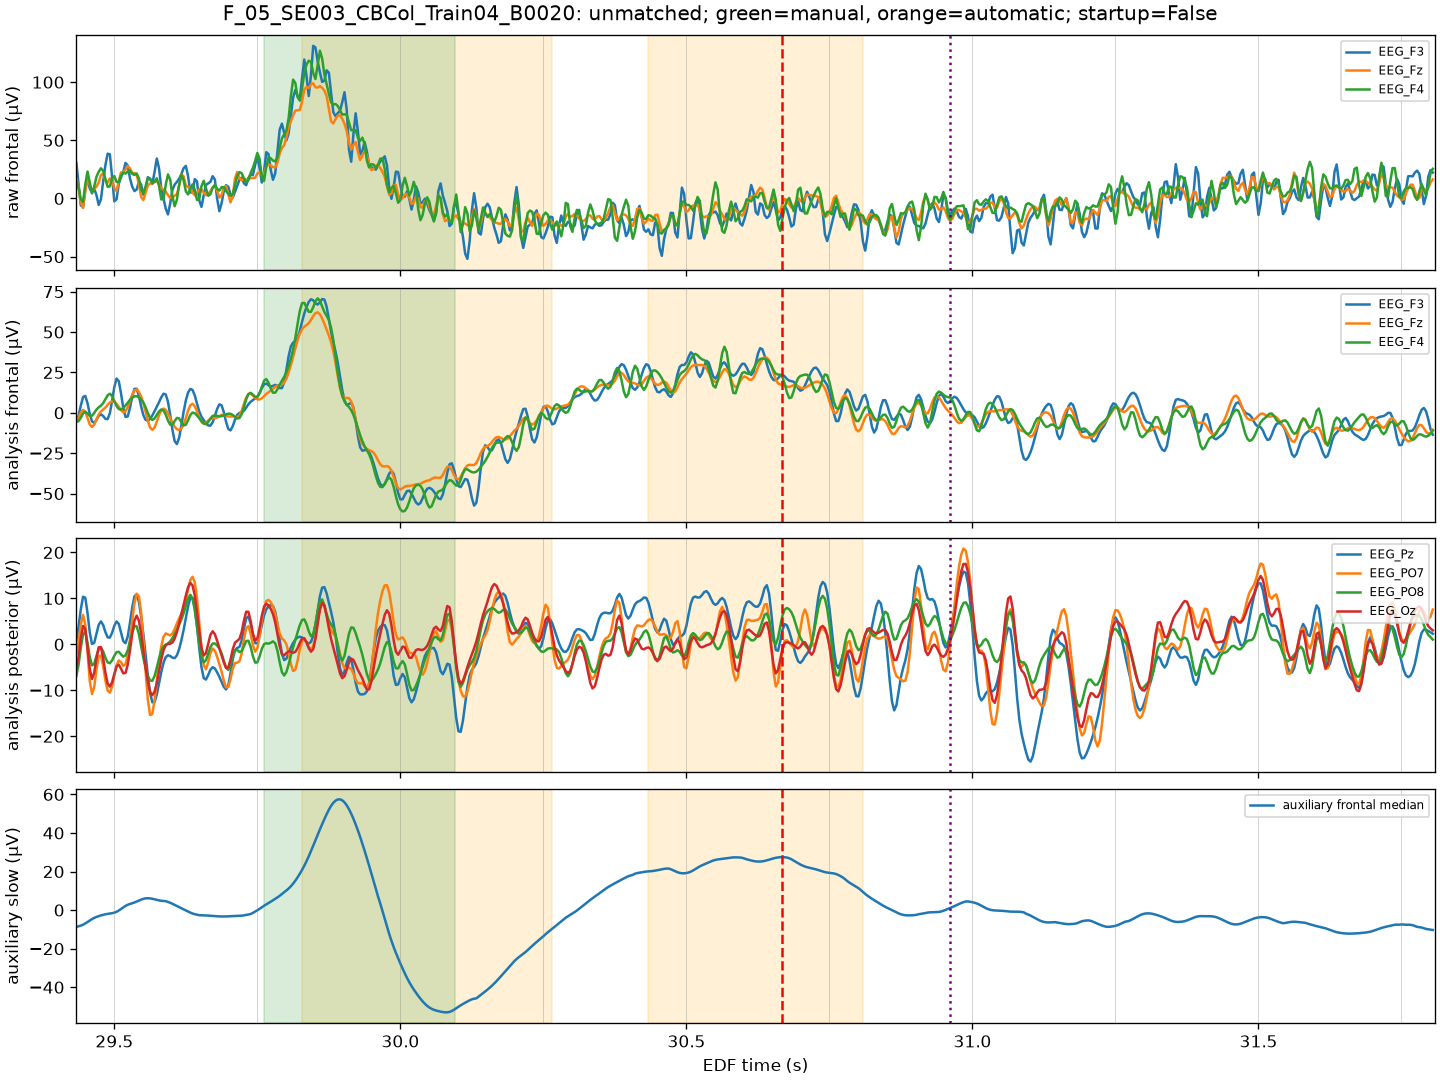

In [5]:
display(Image(filename=str(OUT/'F_05_SE003_CBCol_Train04_B0020.png'),width=1100))

## 当前判断

存在未匹配候选，说明“覆盖已标眨眼很多”不代表没有误报。先针对这3段复核波形，再决定是否需要调整恢复、合并或慢波形态条件；不直接降低幅值阈值，也不为这35秒单独调出最优参数。其他未完整复核的区间仍属于未知。

重新计算并画图：`scripts/inspect_reviewed_blinks.py`。最新全文件人工对照：notebook08。

---

## 历史实验 / 专项复核：bigp3bci_manual_blink_threshold_validation

# 用已保存的人工眨眼标注检查 PTP 阈值

**研究范围：伪迹目标只考虑眨眼。**非有限值、不完整窗口、滤波启动期属于数据可用性检查，和眨眼检出分开统计；不新增肌电、心搏等来源判定，不删除所谓“坏通道”。

你确认：保存的 `MANUAL_bad_span` 实际标的是眨眼，并且每个浏览窗口只标了几个，**还有很多眨眼没有标**。因此这里只把已有区间视为眨眼正例，标注外一律未知。本 notebook 不改原始标注或正式阈值。

结论先看：现有 150/250/350 µV 上限均漏掉全部可评估的已标眨眼 epoch。更低阈值能提高已标样本覆盖，但目前无法判断误删率，所以不能直接确定新阈值。

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'configs/causal_pilot.json').exists())
OUT=ROOT/'outputs/blink_validation'
STEM='F_05_SE001_CBCol_Train02'
BASE=ROOT/'outputs/causal_pilot'/STEM
comparison=pd.read_csv(OUT/'threshold_blink_comparison.csv')
intervals=pd.read_csv(OUT/'manual_interval_detection.csv')
events=pd.read_csv(OUT/'epoch_blink_overlap.csv')
record=json.loads((BASE/'processing_record.json').read_text())
plt.rcParams.update({'figure.dpi':110,'axes.spines.top':False,'axes.spines.right':False})
display(pd.Series(json.loads((OUT/'analysis_record.json').read_text()),name='analysis provenance').to_frame())

,analysis provenance
annotation_source,outputs\artifact_qc\continuous_manual_qc\manua...
semantic_source,User states saved bad spans are blinks; origin...
n_annotations,14
reviewed_coverage,User confirms sparse examples in each viewing ...
label_usage,none in detection
thresholds_changed,False
training_only,True
interval_overlap,"half-open integer sample ranges, ceil annotati..."
scope,blink artifact evaluation; existing data-integ...
frontal_channels,"[EEG_F3, EEG_Fz, EEG_F4]"


## 1. 标注是什么，能评估什么？

找到 F_05_SE001_CBCol_Train02 的 14 段人工标注。保存格式是**时间段**，不是某个 EEG 通道永久损坏。保留原来的 `MANUAL_bad_span` 名称，用本次用户确认说明它们是眨眼，避免重写标注历史。

CSV 时间段与独立 FIF 已核对一致。下面的表保留每段起止时间，便于回到 notebook 04 复核。

能计算：已标眨眼涉及的 epoch 有多少被阈值检出。不能计算：误删率、精确率、所有真实眨眼的召回率。原因是没有经过完整检查的阴性区间，而且你挑选的明显眨眼可能不代表全部眨眼。

In [2]:
display(intervals[['manual_id','start_sec','end_sec','duration_sec','type','overlap_epochs','eligible_overlap_epochs']])
print('标注总数：',len(intervals))
print('不与任何 flash epoch 重叠：',int(intervals.overlap_epochs.eq(0).sum()))
print('至少涉及一个可评估 epoch：',int(intervals.eligible_overlap_epochs.gt(0).sum()))
print('与眨眼重叠的完整、非启动期、非通道待定 epoch：',int((events.manual_blink_overlap & events.evaluation_eligible).sum()))

,manual_id,start_sec,end_sec,duration_sec,type,overlap_epochs,eligible_overlap_epochs
0,F_05_SE001_CBCol_Train02_M0001,1.889938,2.193431,0.303494,MANUAL_bad_span,0,0
1,F_05_SE001_CBCol_Train02_M0002,2.903883,3.248762,0.344879,MANUAL_bad_span,0,0
2,F_05_SE001_CBCol_Train02_M0003,3.828159,4.221321,0.393162,MANUAL_bad_span,0,0
3,F_05_SE001_CBCol_Train02_M0004,10.139447,10.470531,0.331084,MANUAL_bad_span,4,2
4,F_05_SE001_CBCol_Train02_M0005,50.760781,50.974606,0.213825,MANUAL_bad_span,4,4
5,F_05_SE001_CBCol_Train02_M0006,52.147195,52.512767,0.365572,MANUAL_bad_span,5,5
6,F_05_SE001_CBCol_Train02_M0007,53.754332,54.106109,0.351777,MANUAL_bad_span,5,5
7,F_05_SE001_CBCol_Train02_M0008,55.968456,56.251257,0.282801,MANUAL_bad_span,5,5
8,F_05_SE001_CBCol_Train02_M0009,112.195489,112.512778,0.317289,MANUAL_bad_span,5,5
9,F_05_SE001_CBCol_Train02_M0010,113.933680,114.250969,0.317289,MANUAL_bad_span,5,5


标注总数： 14
不与任何 flash epoch 重叠： 3
至少涉及一个可评估 epoch： 11
与眨眼重叠的完整、非启动期、非通道待定 epoch： 48


**本次结果：**前 3 段在 1.89–4.22 秒，发生在首个 flash（4.5 秒）之前，不与任何分析 epoch 重叠，不能算漏检。其余 11 段共涉及 50 个 epoch，其中 2 个仍在启动保护区，剩下 **48 个可用于眨眼阈值比较**。

一个眨眼会影响多个重叠 epoch，所以 48 不是 48 个独立眨眼。下文同时报告 epoch 覆盖和眨眼区间覆盖；“某段至少命中一次”不等于这段影响的所有 epoch 都被拒绝。

## 2. 从人工时间段映射到 epoch

按原始样本位置使用半开区间相交：epoch 为 `[onset, onset+205)`；人工区间端点映射为 `ceil(seconds×256)`。任何样本范围相交都标为已知眨眼重叠，不根据 target/non-target 决定是否相交。

下面用时间轴展示人工区间（红色）与受影响 epoch（橙色）。灰色是启动保护区；绿色是参与此次阈值评估的 epoch 时间点。为了说明映射，第一行展示标注区间编号。

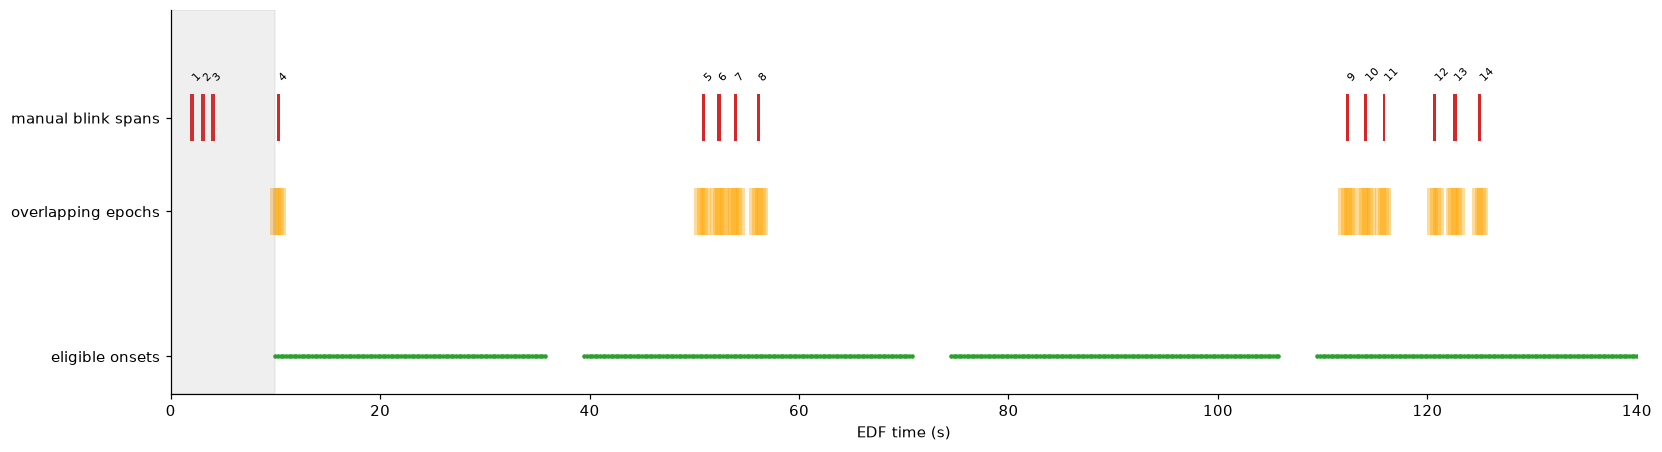

In [3]:
fig,ax=plt.subplots(figsize=(15,4),layout='constrained')
for i,r in intervals.iterrows():
    ax.broken_barh([(r.start_sec,r.end_sec-r.start_sec)],(1.15,.25),facecolors='tab:red')
    ax.text(r.start_sec,1.47,str(i+1),fontsize=7,rotation=45)
positive=events.manual_blink_overlap
for _,r in events[positive].iterrows():
    ax.broken_barh([(r.onset_seconds,record['epoch_samples']/record['sfreq'])],(.65,.25),facecolors='orange',alpha=.4)
ax.scatter(events.loc[events.evaluation_eligible,'onset_seconds'],np.zeros(events.evaluation_eligible.sum()),s=4,color='tab:green')
ax.axvspan(0,10,alpha=.12,color='gray')
ax.set(yticks=[0,.775,1.275],yticklabels=['eligible onsets','overlapping epochs','manual blink spans'],xlabel='EDF time (s)',ylim=(-.2,1.85),xlim=(0,140))
plt.show()

## 3. 原有阈值是否能排除这些眨眼？

把启动期拒绝与眨眼检出分开，仅比较非启动期、完整且无通道策略待定的 734 个 epoch。规则为任意 QC 通道 PTP **大于**上限即触发；这里单独检查高 PTP，因为低 PTP 与眨眼目标无关。

“标注外拒绝数”仍是未知：可能是尚未标出的眨眼，也可能是其他变化，不能称为假阳性。

,upper_uv,eligible_epochs,annotated_blink_epochs,detected_blink_epochs,missed_blink_epochs,annotated_epoch_detection_fraction,intervals_with_any_rejection,rejected_total,rejected_outside_annotation_unknown
0,75,734,48,40,8,0.833333,11,315,275
1,100,734,48,20,28,0.416667,7,162,142
2,125,734,48,2,46,0.041667,1,29,27
3,150,734,48,0,48,0.000000,0,5,5
4,200,734,48,0,48,0.000000,0,3,3
5,250,734,48,0,48,0.000000,0,0,0
6,350,734,48,0,48,0.000000,0,0,0


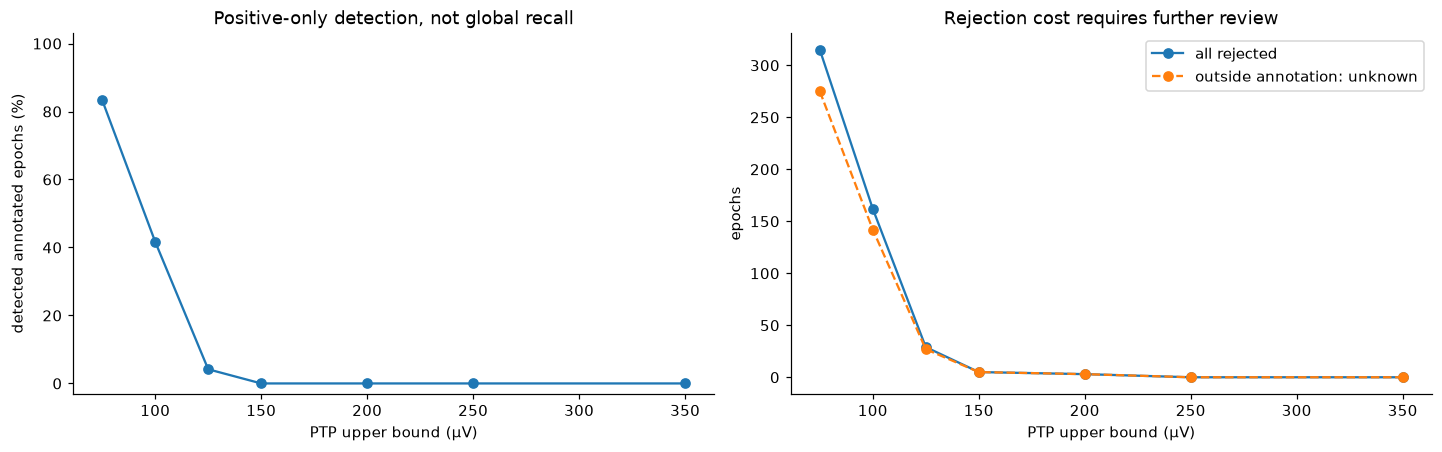

In [4]:
c=comparison[comparison.channel_group.eq('all16')].copy()
display(c[['upper_uv','eligible_epochs','annotated_blink_epochs','detected_blink_epochs','missed_blink_epochs',
           'annotated_epoch_detection_fraction','intervals_with_any_rejection','rejected_total','rejected_outside_annotation_unknown']])
fig,axes=plt.subplots(1,2,figsize=(13,4),layout='constrained')
axes[0].plot(c.upper_uv,c.annotated_epoch_detection_fraction*100,'o-',label='annotated-overlap epochs')
axes[0].set(xlabel='PTP upper bound (µV)',ylabel='detected annotated epochs (%)',ylim=(-3,103),title='Positive-only detection, not global recall')
axes[1].plot(c.upper_uv,c.rejected_total,'o-',label='all rejected')
axes[1].plot(c.upper_uv,c.rejected_outside_annotation_unknown,'o--',label='outside annotation: unknown')
axes[1].set(xlabel='PTP upper bound (µV)',ylabel='epochs',title='Rejection cost requires further review')
axes[1].legend();plt.show()

**本次结果：**

| PTP 上限 | 检出的已标重叠 epoch | 至少命中一次的已标眨眼段 | 全部触发 epoch |
|---|---:|---:|---:|
| 250 µV | 0/48 | 0/11 | 0 |
| 150 µV | 0/48 | 0/11 | 5 |
| 125 µV | 2/48 | 1/11 | 29 |
| 100 µV | 20/48 | 7/11 | 162 |
| 75 µV | 40/48 | 11/11 | 315 |

因此原有阈值对这些眨眼明显太宽松。75 µV 虽命中了全部 11 段中的至少一个 epoch，仍漏掉 8 个重叠 epoch，并触发 315/734（42.9%）个 epoch；其中 275 个标注外触发尚不知对错。**不能据此把正式阈值直接改为 75 µV。**

以上数值是同一训练文件上的探索，不是独立验证性能；候选较低阈值应作为后续复核对象。

## 4. 为什么标了眨眼，PTP 却没有超过 150 µV？

下图按 epoch 画滤波后最大 PTP：橙色为已标眨眼相交，灰色为标注外未知。图中只做描述，不把灰色视为正常对照。

各标注区间再显示 F3/Fz/F4 的因果滤波波形，帮助判断已有标注边界和幅值；纵轴为 µV。眨眼不必超过固定 150 µV，且同一眨眼在不同 epoch 中截到的部分不同，PTP 也会不同。

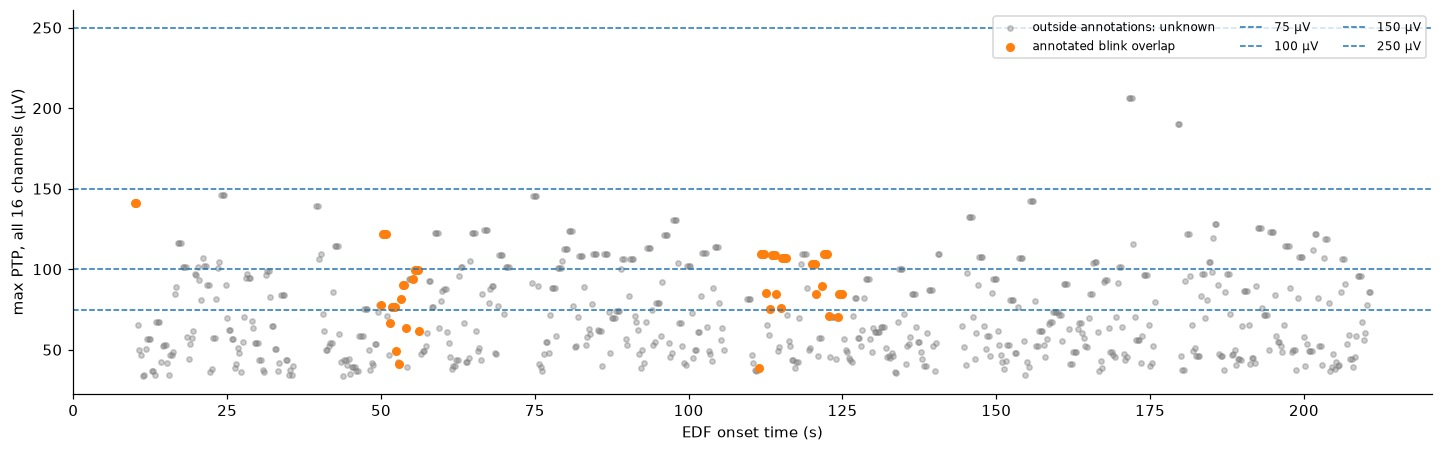

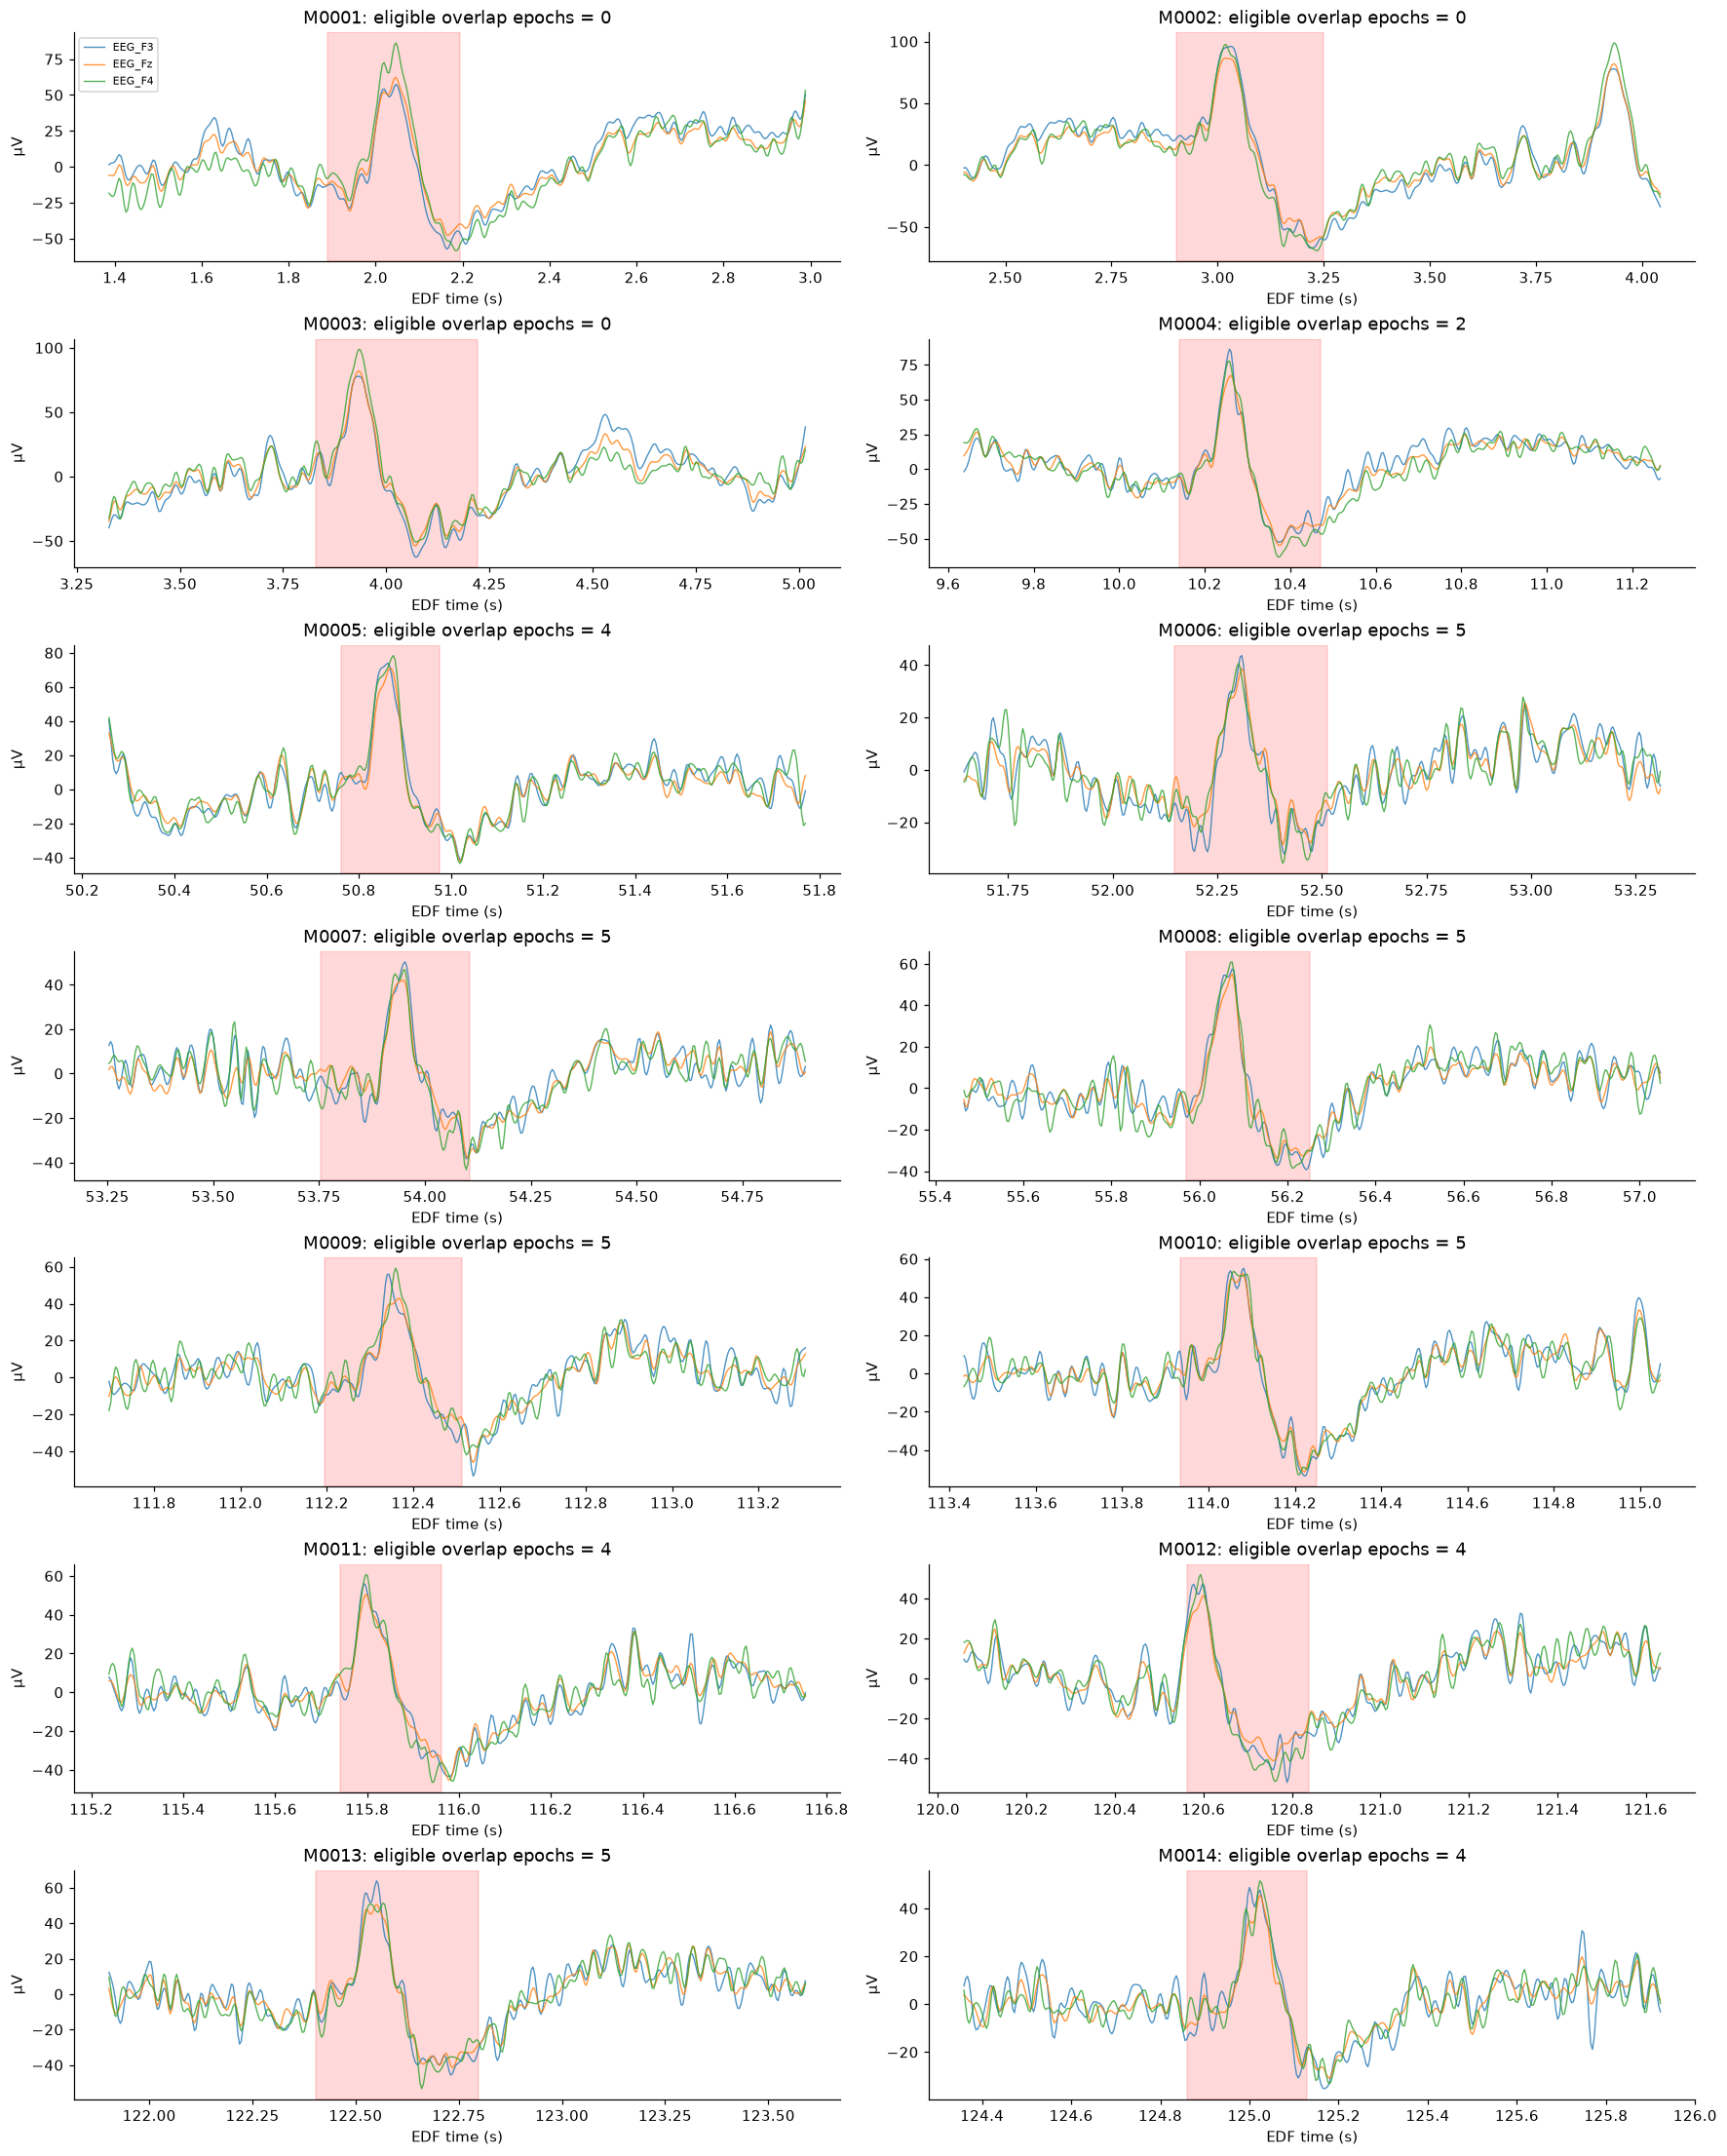

In [5]:
fig,ax=plt.subplots(figsize=(13,4),layout='constrained')
u=events.evaluation_eligible
ax.scatter(events.loc[u & ~positive,'onset_seconds'],events.loc[u & ~positive,'max_ptp_all_uv'],s=12,color='gray',alpha=.4,label='outside annotations: unknown')
ax.scatter(events.loc[u & positive,'onset_seconds'],events.loc[u & positive,'max_ptp_all_uv'],s=24,color='tab:orange',label='annotated blink overlap')
for h in [75,100,150,250]:ax.axhline(h,ls='--',lw=1,label=f'{h} µV')
ax.set(xlabel='EDF onset time (s)',ylabel='max PTP, all 16 channels (µV)');ax.legend(ncol=3,fontsize=8);plt.show()
with np.load(BASE/'continuous_causal_eeg.npz') as data:
    y=data['eeg_v'];channels=data['channels'].tolist();fs=float(data['sfreq'])
fig,axes=plt.subplots(7,2,figsize=(16,20),layout='constrained')
for ax,(_,r) in zip(axes.flat,intervals.iterrows()):
    a=max(0,int((r.start_sec-.5)*fs));b=min(y.shape[1],int((r.end_sec+.8)*fs))
    for ch in ['EEG_F3','EEG_Fz','EEG_F4']:
        ax.plot(np.arange(a,b)/fs,y[channels.index(ch),a:b]*1e6,label=ch,alpha=.8,lw=.9)
    ax.axvspan(r.start_sec,r.end_sec,color='red',alpha=.15)
    ax.set(title=f'{r.manual_id[-5:]}: eligible overlap epochs = {r.eligible_overlap_epochs}',xlabel='EDF time (s)',ylabel='µV')
axes.flat[0].legend(fontsize=7);plt.show()

## 5. 只看额部通道能改善吗？边界扩展会怎样？

额部三通道 F3/Fz/F4 是一个可检查的候选，不是已经确认的眨眼专用传感器，也不改变正式 QC 通道集合。下表比较全 16 通道与额部三通道的已标样本覆盖及拒绝数量。

人工标注来自原始波形，而 QC 使用因果滤波信号，滤波响应可能延伸到原始标注末尾以后。第二张表额外向后扩展 0.25/0.5 秒，只做敏感性分析，**不把扩展区间宣布为新的真实标注，也不移动事件**。

In [6]:
display(comparison[['channel_group','upper_uv','detected_blink_epochs','annotated_blink_epochs','rejected_total','rejected_outside_annotation_unknown']])
display(pd.read_csv(OUT/'padding_sensitivity.csv'))

,channel_group,upper_uv,detected_blink_epochs,annotated_blink_epochs,rejected_total,rejected_outside_annotation_unknown
0,all16,75,40,48,315,275
1,all16,100,20,48,162,142
2,all16,125,2,48,29,27
3,all16,150,0,48,5,5
4,all16,200,0,48,3,3
5,all16,250,0,48,0,0
6,all16,350,0,48,0,0
7,frontal3_exploratory,75,39,48,282,243
8,frontal3_exploratory,100,20,48,150,130
9,frontal3_exploratory,125,2,48,21,19


,post_annotation_padding_seconds,upper_uv,positive_epochs,detected,recall_on_provisional_spans
0,0.00,75,48,40,0.833333
1,0.00,100,48,20,0.416667
2,0.00,125,48,2,0.041667
3,0.00,150,48,0,0.000000
4,0.00,250,48,0,0.000000
5,0.25,75,59,40,0.677966
6,0.25,100,59,20,0.338983
7,0.25,125,59,2,0.033898
8,0.25,150,59,0,0.000000
9,0.25,250,59,0,0.000000


**如何判断：**PTP 是幅值指标，不具备眨眼来源特异性。即使额部限制减少标注外触发，也要靠完整检查的眨眼/非眨眼区间验证；不能仅凭正例覆盖就选出规则。若单一幅值阈值始终无法兼顾漏检和保留，再讨论增加眨眼形态或额部分布指标，当前不自动实施。

## 6. 还需要手动标注吗？优先标什么？

**需要补充，但先不要求标完整份或所有文件。**当前最缺的是“完整检查的连续区间”，而不只是更多明显眨眼正例。

建议先对两份训练 pilot 各完整复核 6 段、每段约 10 秒（合计约两分钟 EEG）。下面给出高 PTP、100 µV 附近、随机位置的优先片段。这是降低初轮复核工作量的起点，不是样本量充分的保证；特意富集的片段不能用于估计自然分布下的总体误删率。

逐段操作：

1. 在 notebook 04 打开对应 EDF，完整检查表中起止区间，标出**所有**眨眼，用 `MANUAL_blink`；不确定处标 `MANUAL_uncertain`，不要强判。
2. 显式记录这段已经完整检查。只有在已检查区间内、扣除眨眼和不确定片段后，才可构成已核查的无眨眼区域。眨眼范围要覆盖看到的完整波形过程，不要只标峰顶。
3. 如果看到了非眨眼的大幅变化，可以记录 `MANUAL_other_transient` 供核对，但不因此自动作为眨眼拒绝。NaN、缺失窗口等另归数据可用性检查。
4. 下一阶段用训练开发部分调候选规则，再用另外的训练文件/subject/session 独立验证；不要把重叠 epoch 随机拆开当独立样本。不同 calibration budget 仍须遵守其可见训练数据范围。

以下时间段尚未复核，review_status 保持 not_reviewed。建议表不会覆盖你的原始 annotation，也不会自动生成“正常”标签。

In [7]:
display(pd.read_csv(OUT/'suggested_review_intervals.csv'))
print('复核建议表：',OUT/'suggested_review_intervals.csv')

,site_inferred,edf_name,start_sec,end_sec,selection_reason,review_status,instruction
0,Duke,F_05_SE001_CBCol_Train02.edf,166.75,176.75,high PTP: blink or another transient?,not_reviewed,Review entire interval; annotate every blink a...
1,Duke,F_05_SE001_CBCol_Train02.edf,19.25,29.25,high PTP: blink or another transient?,not_reviewed,Review entire interval; annotate every blink a...
2,Duke,F_05_SE001_CBCol_Train02.edf,129.25,139.25,near exploratory 100uV cutoff,not_reviewed,Review entire interval; annotate every blink a...
3,Duke,F_05_SE001_CBCol_Train02.edf,84.00,94.00,near exploratory 100uV cutoff,not_reviewed,Review entire interval; annotate every blink a...
4,Duke,F_05_SE001_CBCol_Train02.edf,184.75,194.75,"random epoch-centered block, review full interval",not_reviewed,Review entire interval; annotate every blink a...
5,Duke,F_05_SE001_CBCol_Train02.edf,107.50,117.50,"random epoch-centered block, review full interval",not_reviewed,Review entire interval; annotate every blink a...
6,ETSU,F_03_SE001_CBCol_Train01.edf,92.75,102.75,high PTP: blink or another transient?,not_reviewed,Review entire interval; annotate every blink a...
7,ETSU,F_03_SE001_CBCol_Train01.edf,197.50,207.50,high PTP: blink or another transient?,not_reviewed,Review entire interval; annotate every blink a...
8,ETSU,F_03_SE001_CBCol_Train01.edf,169.75,179.75,near exploratory 100uV cutoff,not_reviewed,Review entire interval; annotate every blink a...
9,ETSU,F_03_SE001_CBCol_Train01.edf,123.00,133.00,near exploratory 100uV cutoff,not_reviewed,Review entire interval; annotate every blink a...


复核建议表： D:\BCI_project\bigp3bci-personalized-strategies\outputs\blink_validation\suggested_review_intervals.csv


## 7. 检查与本次决策

暂时保留原有正式配置，把它视为通用大幅异常的宽松候选；**尚不能宣称它满足“只排除眨眼”的目标**。已有人工标注已足以否定 150/250/350 µV 对本组眨眼的检出能力，但不足以选定更低最终阈值。等待完整检查区间与独立训练验证后再冻结眨眼规则。

分析产物在 `outputs/blink_validation`，重复计算用 `scripts/evaluate_manual_blinks.py`。正式 preprocessing 配置、原始 EDF、原始人工标注均未更改。有效性检查与眨眼伪迹判定继续分开保留。

In [8]:
assert len(intervals)==14
assert int((events.manual_blink_overlap & events.evaluation_eligible).sum())==48
assert comparison.loc[(comparison.channel_group=='all16') & (comparison.upper_uv>=150),'detected_blink_epochs'].eq(0).all()
assert comparison.precision.isna().all() and comparison.false_positive_rate.isna().all()
assert events.loc[~events.manual_blink_overlap,'reference_status'].eq('unknown_unreviewed_coverage').all()
print('PASS: 正例重叠、评估分母与未知区间处理检查通过；未计算无依据的误删率。')

PASS: 正例重叠、评估分母与未知区间处理检查通过；未计算无依据的误删率。
